# Online Retail Customer Segmentation Using RFM Analysis


## 1. Import Libraries & Load Dataset

In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset
df = pd.read_csv("data.csv", encoding="ISO-8859-1")

# Dataset Overview
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

First 5 Rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB



### Key Insights & Recommendations

Dataset Online Retail terdiri dari 541,909 baris dan 8 kolom yang mencakup informasi transaksi, produk, pelanggan, dan penjualan. Dataset memiliki variabel utama untuk RFM Analysis, tetapi masih memerlukan validasi kualitas dan tipe data. Perusahaan perlu memastikan pencatatan transaksi yang konsisten agar analisis perilaku pelanggan dan strategi customer retention dapat dilakukan secara akurat.


## 2. Dataset Overview & Descriptive Statistics

In [2]:

# Numerical Descriptive Statistics
print("Numerical Descriptive Statistics:")
display(
    df[["Quantity", "UnitPrice"]].describe().T
)

# Categorical Descriptive Statistics
print("\nCategorical Descriptive Statistics:")
display(
    df[["InvoiceNo", "StockCode", "Description", "Country"]]
    .describe().T
)

# Unique Values
print("\nUnique Values per Column:")
display(
    df.nunique(dropna=True).reset_index(
        name="Unique Values"
    ).rename(columns={"index": "Column"})
)

# Key Dataset Information
print("\nUnique Customers:", df["CustomerID"].nunique())
print("Unique Invoices:", df["InvoiceNo"].nunique())
print("Unique Products:", df["StockCode"].nunique())
print("Unique Countries:", df["Country"].nunique())


Numerical Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
Quantity,541909.0,9.552250,218.081158,-80995.00,1.00,3.00,10.00,80995.0
UnitPrice,541909.0,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0



Categorical Descriptive Statistics:


,count,unique,top,freq
InvoiceNo,541909,25900,573585,1114
StockCode,541909,4070,85123A,2313
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369
Country,541909,38,United Kingdom,495478



Unique Values per Column:


,Column,Unique Values
0,InvoiceNo,25900
1,StockCode,4070
2,Description,4223
3,Quantity,722
4,InvoiceDate,23260
5,UnitPrice,1630
6,CustomerID,4372
7,Country,38



Unique Customers: 4372
Unique Invoices: 25900
Unique Products: 4070
Unique Countries: 38



### Key Insights & Recommendations

Dataset mencakup 4,372 pelanggan unik, 25,900 invoice, 4,070 produk, dan 38 negara, dengan 91.43% baris transaksi berasal dari United Kingdom. Dominasi pasar tersebut menunjukkan tingginya konsentrasi aktivitas bisnis pada satu negara. Perusahaan disarankan mempertahankan pasar utama, mengevaluasi peluang ekspansi internasional, serta memanfaatkan RFM Analysis untuk mengidentifikasi pelanggan bernilai tinggi dan meningkatkan customer retention.



## 3. Data Inconsistency Check


In [3]:

# Temporary Date Conversion for Validation
date_check = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

# Identify Cancellation Invoices
cancelled = (
    df["InvoiceNo"]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.startswith("C")
)

# Data Inconsistency Summary
inconsistency = pd.DataFrame({
    "Check": [
        "Invalid InvoiceDate",
        "Negative Quantity",
        "Zero Quantity",
        "Negative UnitPrice",
        "Zero UnitPrice",
        "Cancelled Invoice",
        "Cancelled Invoice with Non-Negative Quantity",
        "Negative Quantity without Cancellation",
        "Invalid CustomerID Format"
    ],
    "Count": [
        date_check.isna().sum(),
        (df["Quantity"] < 0).sum(),
        (df["Quantity"] == 0).sum(),
        (df["UnitPrice"] < 0).sum(),
        (df["UnitPrice"] == 0).sum(),
        cancelled.sum(),
        (cancelled & (df["Quantity"] >= 0)).sum(),
        ((~cancelled) & (df["Quantity"] < 0)).sum(),
        (
            df["CustomerID"].notna() &
            (df["CustomerID"] % 1 != 0)
        ).sum()
    ]
})

# Calculate Percentage
inconsistency["Percentage (%)"] = (
    inconsistency["Count"] / len(df) * 100
).round(2)

display(inconsistency)

# Check if InvoiceNo Belongs to Multiple Customers
invoice_customer = (
    df.groupby("InvoiceNo")["CustomerID"]
    .nunique()
)

print(
    "Invoices Linked to Multiple Customers:",
    (invoice_customer > 1).sum()
)

print("\nDataset Shape:", df.shape)


,Check,Count,Percentage (%)
0,Invalid InvoiceDate,0,0.00
1,Negative Quantity,10624,1.96
2,Zero Quantity,0,0.00
3,Negative UnitPrice,2,0.00
4,Zero UnitPrice,2515,0.46
5,Cancelled Invoice,9288,1.71
6,Cancelled Invoice with Non-Negative Quantity,0,0.00
7,Negative Quantity without Cancellation,1336,0.25
8,Invalid CustomerID Format,0,0.00


Invoices Linked to Multiple Customers: 0

Dataset Shape: (541909, 8)



### Key Insights & Recommendations

Ditemukan 10,624 baris (1.96%) dengan Quantity negatif, 9,288 baris cancellation, serta 2,517 baris dengan UnitPrice nol atau negatif. Kondisi ini menunjukkan adanya indikasi transaksi retur, pembatalan, atau kemungkinan penyesuaian stok yang dapat memengaruhi perhitungan revenue. Perusahaan disarankan menerapkan klasifikasi transaksi yang konsisten dan validasi otomatis pada sistem pencatatan agar perhitungan Net Revenue serta customer value dalam RFM Analysis lebih akurat.



### Data Format Consistency Validation


In [4]:

# Define Text Columns
text_cols = [
    "InvoiceNo", "StockCode",
    "Description", "Country"
]

consistency_results = []

for col in text_cols:

    original = df[col].astype("string")

    # Standardize for Comparison Only
    stripped = original.str.strip()
    normalized = stripped.str.upper()

    # Detect Formatting Issues
    whitespace = (
        original.notna() &
        original.ne(stripped)
    ).fillna(False)

    empty_strings = (
        stripped == ""
    ).fillna(False)

    consistency_results.append({
        "Column": col,
        "Whitespace Issues": whitespace.sum(),
        "Empty Strings": empty_strings.sum(),
        "Unique Before": original.nunique(),
        "Unique After": normalized.nunique(),
        "Unique Difference": (
            original.nunique() -
            normalized.nunique()
        )
    })

# Display Summary
consistency_summary = pd.DataFrame(consistency_results)

print("Data Format Consistency Summary:")
display(consistency_summary)

# Dataset Validation
print("\nDataset Shape:", df.shape)


Data Format Consistency Summary:


,Column,Whitespace Issues,Empty Strings,Unique Before,Unique After,Unique Difference
0,InvoiceNo,0,0,25900,25900,0
1,StockCode,0,0,4070,3958,112
2,Description,113452,0,4223,4194,29
3,Country,0,0,38,38,0



Dataset Shape: (541909, 8)



### Key Insights & Recommendations

Data Format Validation menemukan 113,452 baris Description dengan spasi berlebih serta penurunan unique StockCode dari 4,070 menjadi 3,958 setelah normalisasi. Kondisi ini menunjukkan adanya ketidakkonsistenan format yang berpotensi memengaruhi identifikasi produk dan agregasi transaksi. Perusahaan disarankan menerapkan standardisasi penulisan dan validasi otomatis pada sistem pencatatan produk untuk meningkatkan konsistensi data.


### Format Variants Investigation

In [5]:

# Investigate Formatting Variations
for col in ["StockCode", "Description"]:

    temp = pd.DataFrame({
        "Original": df[col].dropna().astype("string")
    })

    temp["Normalized"] = (
        temp["Original"].str.strip().str.upper()
    )

    # Identify Categories with Multiple Original Variants
    variants = (
        temp.groupby("Normalized")["Original"]
        .nunique()
        .sort_values(ascending=False)
    )

    variants = variants[variants > 1]

    print(f"\n{col} - Categories with Format Variations:")
    print("Total Groups:", len(variants))

    # Show Examples
    examples = (
        temp[temp["Normalized"].isin(variants.head(10).index)]
        .drop_duplicates()
        .sort_values("Normalized")
    )

    display(examples.head(30))



StockCode - Categories with Format Variations:
Total Groups: 112


,Original,Normalized
133,15056N,15056N
15801,15056n,15056N
2307,15056P,15056P
5371,15056p,15056P
4310,15060B,15060B
349415,15060b,15060B
1858,18098C,18098C
5548,18098c,18098C
15504,35809A,35809A
21922,35809a,35809A



Description - Categories with Format Variations:
Total Groups: 26


,Original,Normalized
112219,Adjustment,ADJUSTMENT
166639,adjustment,ADJUSTMENT
6391,amazon,AMAZON
344080,Amazon,AMAZON
499887,AMAZON,AMAZON
3950,COLUMBIAN CANDLE ROUND,COLUMBIAN CANDLE ROUND
7070,COLUMBIAN CANDLE ROUND,COLUMBIAN CANDLE ROUND
170542,crushed,CRUSHED
331018,Crushed,CRUSHED
142631,Damaged,DAMAGED



### Key Insights & Recommendations

Data Format Investigation menemukan 112 kelompok StockCode dan 26 kelompok Description dengan variasi penulisan, termasuk perbedaan huruf besar/kecil dan spasi. Ketidakkonsistenan ini berpotensi menyebabkan produk yang sama tercatat sebagai kategori berbeda. Perusahaan disarankan menerapkan standardisasi format StockCode dan Description untuk meningkatkan akurasi identifikasi produk, agregasi penjualan, dan analisis customer value.


## 4. Missing Values Assessment

,Missing Values,Percentage (%)
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


Total Missing Values: 136534
Rows With Missing Values: 135080


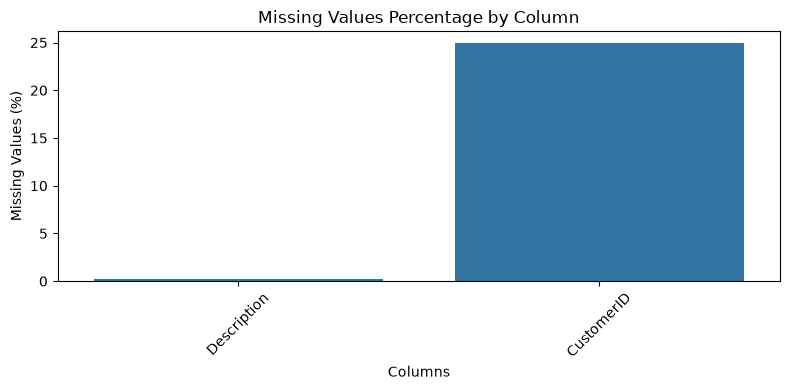

In [6]:

# Missing Values Assessment
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage (%)": (
        df.isnull().mean() * 100
    ).round(2)
})

# Display Summary
display(missing)

# Total Missing Values
print("Total Missing Values:", df.isnull().sum().sum())

# Rows With At Least One Missing Value
print(
    "Rows With Missing Values:",
    df.isnull().any(axis=1).sum()
)

# Missing Values Visualization
missing_plot = missing[missing["Missing Values"] > 0]

plt.figure(figsize=(8, 4))

sns.barplot(
    x=missing_plot.index,
    y=missing_plot["Percentage (%)"]
)

plt.title("Missing Values Percentage by Column")
plt.xlabel("Columns")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



### Key Insights & Recommendations

Ditemukan 135,080 missing values pada CustomerID (24.93%) dan 1,454 pada Description (0.27%). Tingginya missing CustomerID menyebabkan hampir seperempat baris transaksi tidak dapat digunakan untuk segmentasi pelanggan. Perusahaan disarankan meningkatkan kelengkapan identitas pelanggan melalui integrasi POS dengan CRM atau loyalty program agar analisis RFM dan strategi customer retention lebih akurat.



## 5. Duplicate Assessment


In [7]:

# Identify Duplicate Rows
duplicate_mask = df.duplicated(keep=False)
extra_duplicates = df.duplicated(keep="first")

# Duplicate Summary
print("Total Rows:", len(df))
print("Rows in Duplicate Groups:", duplicate_mask.sum())
print("Extra Duplicate Rows:", extra_duplicates.sum())

print(
    "Duplicate Percentage:",
    round(extra_duplicates.mean() * 100, 2), "%"
)

# Duplicate Assessment by CustomerID Availability
print("\nDuplicate Rows with Valid CustomerID:")
print(
    df.loc[df["CustomerID"].notna()]
    .duplicated().sum()
)

print("\nDuplicate Rows with Missing CustomerID:")
print(
    df.loc[df["CustomerID"].isna()]
    .duplicated().sum()
)

# Top Duplicate Groups
duplicate_groups = (
    df.loc[duplicate_mask]
    .groupby(df.columns.tolist(), dropna=False)
    .size()
    .reset_index(name="Occurrences")
    .sort_values("Occurrences", ascending=False)
)

print("\nTop 10 Duplicate Groups:")
display(
    duplicate_groups[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Occurrences"]
    ].head(10)
)


Total Rows: 541909
Rows in Duplicate Groups: 10147
Extra Duplicate Rows: 5268
Duplicate Percentage: 0.97 %

Duplicate Rows with Valid CustomerID:
5225

Duplicate Rows with Missing CustomerID:
43

Top 10 Duplicate Groups:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Occurrences
1613,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2.95,20
1612,555524,22697,GREEN REGENCY TEACUP AND SAUCER,1,2.95,12
3202,572861,22775,PURPLE DRAWERKNOB ACRYLIC EDWARDIAN,12,1.25,8
3146,572344,M,Manual,48,1.50,6
474,540524,21756,BATH BUILDING BLOCK WORD,1,5.95,6
4249,578289,23395,BELLE JARDINIERE CUSHION COVER,1,3.75,6
528,541266,21754,HOME BUILDING BLOCK WORD,1,5.95,6
347,538514,21756,BATH BUILDING BLOCK WORD,1,5.95,6
529,541266,21755,LOVE BUILDING BLOCK WORD,1,5.95,6
186,537224,70007,HI TEC ALPINE HAND WARMER,1,1.65,5


In [8]:

# Define Original Transaction Columns
transaction_cols = [
    "InvoiceNo", "StockCode", "Description",
    "Quantity", "InvoiceDate", "UnitPrice",
    "CustomerID", "Country"
]

# Identify Exact Duplicate Groups
duplicate_examples = (
    df.groupby(transaction_cols, dropna=False)
    .size()
    .reset_index(name="Occurrences")
)

# Filter Groups with More Than One Occurrence
duplicate_examples = (
    duplicate_examples[
        duplicate_examples["Occurrences"] > 1
    ]
    .sort_values("Occurrences", ascending=False)
)

print("Top 10 Exact Duplicate Transaction Groups:")
display(duplicate_examples.head(10))

# Investigate One Example in Detail
example = duplicate_examples.iloc[0]

mask = pd.Series(True, index=df.index)

for col in transaction_cols:
    if pd.isna(example[col]):
        mask &= df[col].isna()
    else:
        mask &= df[col].eq(example[col]).fillna(False)

print("\nDetailed Duplicate Transaction Example:")
display(
    df.loc[mask, transaction_cols]
)

print("\nNumber of Identical Rows:", mask.sum())

print(
    "Total Recorded Quantity:",
    df.loc[mask, "Quantity"].sum()
)

print(
    "Total Recorded Value: £",
    round(
        (
            df.loc[mask, "Quantity"] *
            df.loc[mask, "UnitPrice"]
        ).sum(), 2
    )
)


Top 10 Exact Duplicate Transaction Groups:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Occurrences
207580,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,6/5/2011 11:37,2.95,16923.0,United Kingdom,20
207579,555524,22697,GREEN REGENCY TEACUP AND SAUCER,1,6/5/2011 11:37,2.95,16923.0,United Kingdom,12
408646,572861,22775,PURPLE DRAWERKNOB ACRYLIC EDWARDIAN,12,10/26/2011 12:46,1.25,14102.0,United Kingdom,8
403109,572344,M,Manual,48,10/24/2011 10:43,1.50,14607.0,United Kingdom,6
48190,540524,21756,BATH BUILDING BLOCK WORD,1,1/9/2011 12:53,5.95,16735.0,United Kingdom,6
481780,578289,23395,BELLE JARDINIERE CUSHION COVER,1,11/23/2011 14:07,3.75,17841.0,United Kingdom,6
57332,541266,21754,HOME BUILDING BLOCK WORD,1,1/16/2011 16:25,5.95,15673.0,United Kingdom,6
25695,538514,21756,BATH BUILDING BLOCK WORD,1,12/12/2010 14:27,5.95,15044.0,United Kingdom,6
57333,541266,21755,LOVE BUILDING BLOCK WORD,1,1/16/2011 16:25,5.95,15673.0,United Kingdom,6
9744,537224,70007,HI TEC ALPINE HAND WARMER,1,12/5/2010 16:24,1.65,13174.0,United Kingdom,5



Detailed Duplicate Transaction Example:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
213176,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,6/5/2011 11:37,2.95,16923.0,United Kingdom
213177,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,6/5/2011 11:37,2.95,16923.0,United Kingdom
213183,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,6/5/2011 11:37,2.95,16923.0,United Kingdom
213191,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,6/5/2011 11:37,2.95,16923.0,United Kingdom
213192,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,6/5/2011 11:37,2.95,16923.0,United Kingdom
213194,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,6/5/2011 11:37,2.95,16923.0,United Kingdom
213195,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,6/5/2011 11:37,2.95,16923.0,United Kingdom
213196,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,6/5/2011 11:37,2.95,16923.0,United Kingdom
213197,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,6/5/2011 11:37,2.95,16923.0,United Kingdom
213198,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,6/5/2011 11:37,2.95,16923.0,United Kingdom



Number of Identical Rows: 20
Total Recorded Quantity: 20
Total Recorded Value: £ 59.0



### Key Insights & Recommendations

Ditemukan 5,268 duplicate rows (0.97%) dari total transaksi, dengan mayoritas duplikasi memiliki CustomerID yang valid. Kondisi ini berpotensi menyebabkan perhitungan Monetary terlalu tinggi jika duplikasi merupakan kesalahan pencatatan. Perusahaan disarankan menggunakan unique transaction line ID dan melakukan validasi duplikasi secara berkala agar nilai pembelian pelanggan lebih akurat, tanpa menghapus transaksi identik yang belum terbukti salah.



## 6. Frequency Encoding & IQR Outlier Detection


IQR Outlier Summary:


,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier (%)
0,InvoiceNo,22.00,118.00,96.00,-122.00,262.00,63627,11.74
1,StockCode,154.00,578.00,424.00,-482.00,1214.00,26101,4.82
2,Description,152.00,573.00,421.00,-479.50,1204.50,25929,4.78
3,Quantity,1.00,10.00,9.00,-12.50,23.50,58619,10.82
4,InvoiceDate,117.13,322.13,205.00,-190.36,629.62,0,0.00
5,UnitPrice,1.25,4.13,2.88,-3.07,8.45,39627,7.31
6,CustomerID,123.00,7983.00,7860.00,-11667.00,19773.00,135080,24.93
7,Country,495478.00,495478.00,0.00,495478.00,495478.00,46431,8.57


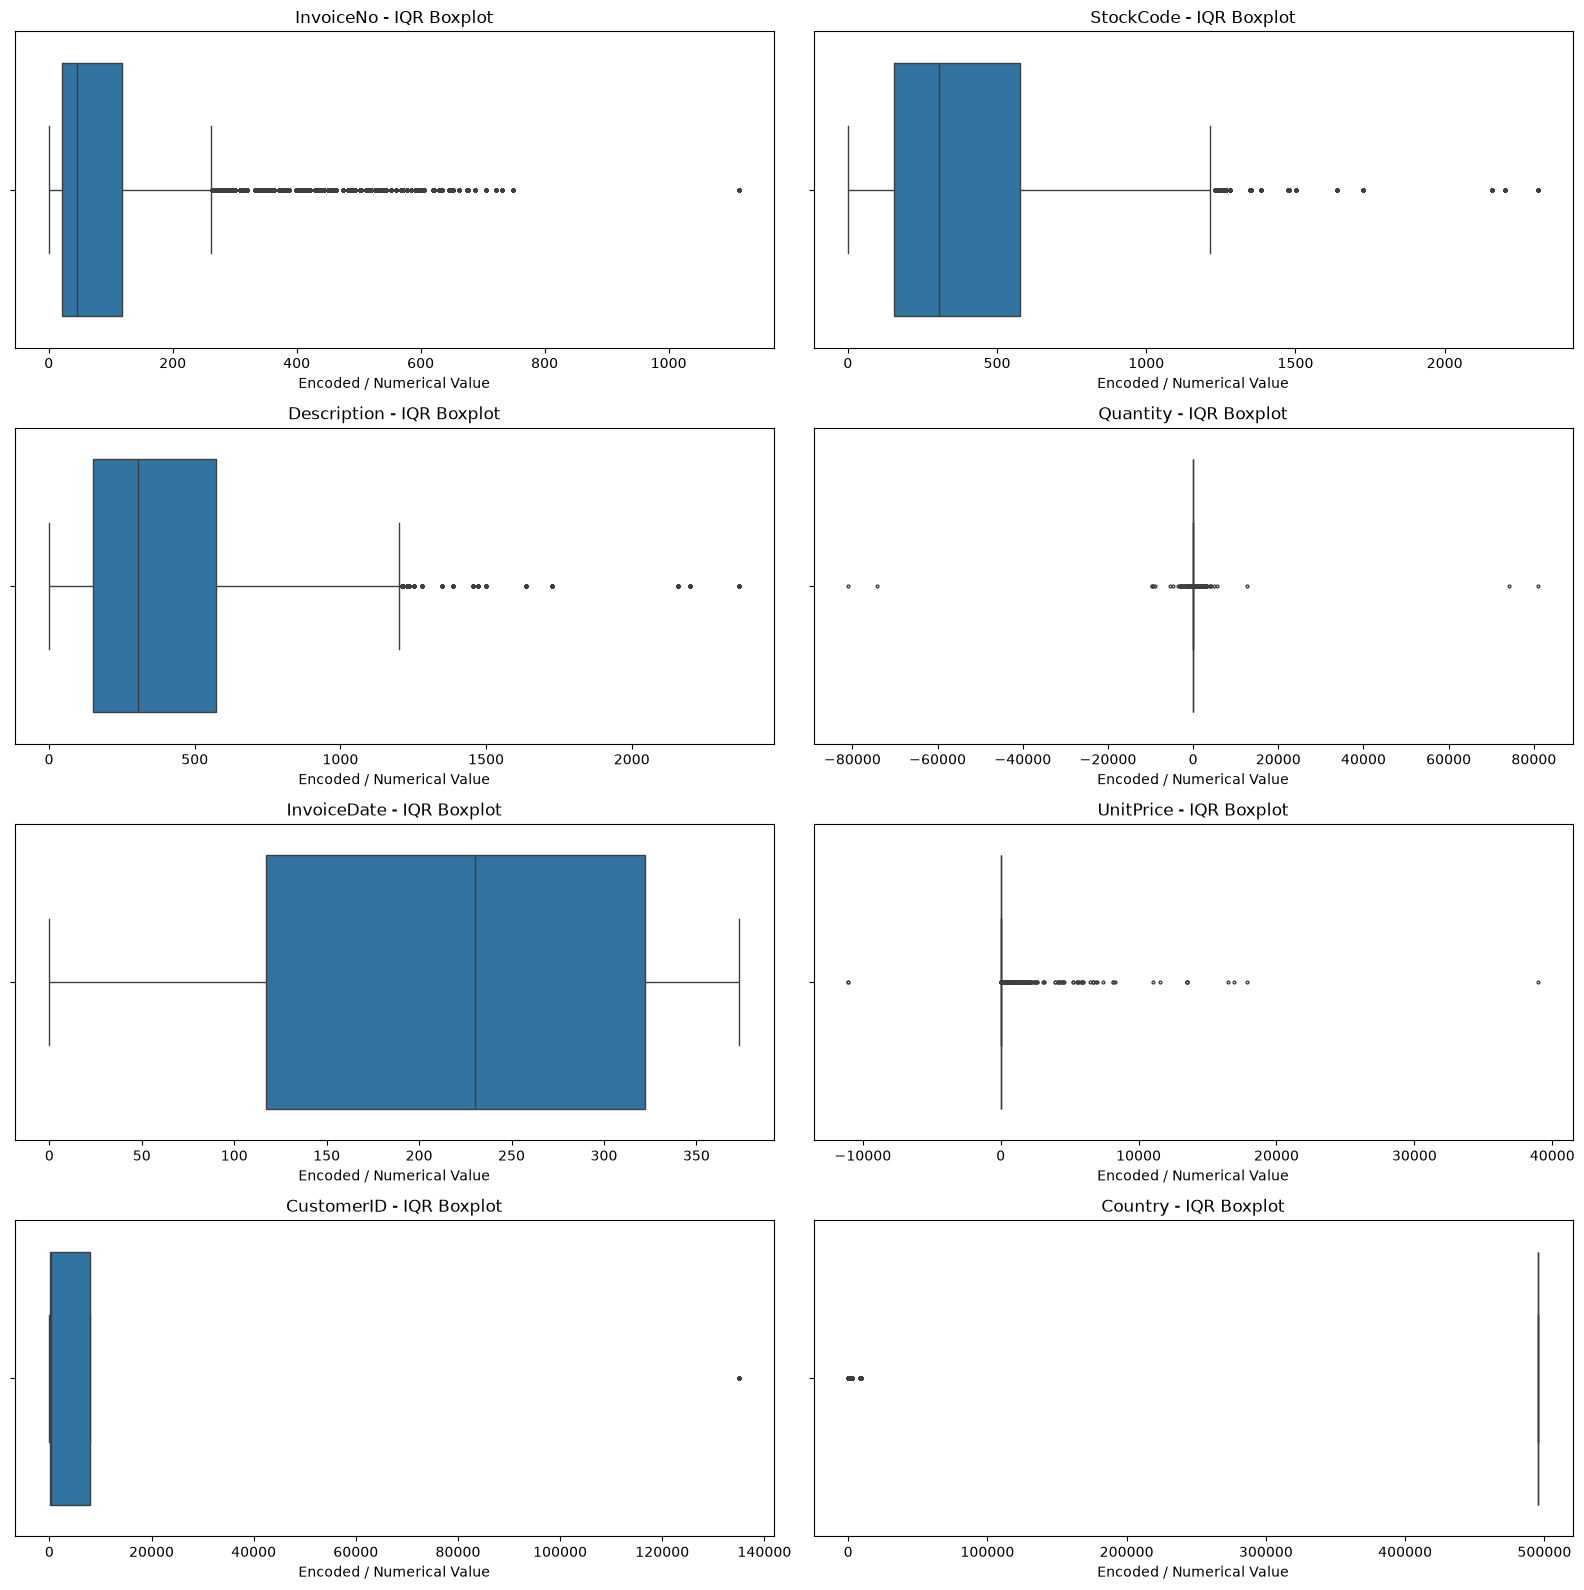

Original Dataset Shape: (541909, 8)
Encoded Dataset Shape: (541909, 8)


In [9]:

# Create Encoded Dataset
df_encoded = pd.DataFrame(index=df.index)

# Categorical Columns
categorical_cols = [
    "InvoiceNo", "StockCode", "Description",
    "CustomerID", "Country"
]

# Frequency Encoding
for col in categorical_cols:
    values = df[col].astype("string").fillna("MISSING")
    frequency = values.value_counts()
    df_encoded[col] = values.map(frequency).astype(int)

# Numerical Columns (Keep Original Values)
df_encoded["Quantity"] = df["Quantity"]
df_encoded["UnitPrice"] = df["UnitPrice"]

# Date Conversion (Days Since First Transaction)
dates = pd.to_datetime(df["InvoiceDate"], errors="coerce")

df_encoded["InvoiceDate"] = (
    (dates - dates.min()).dt.total_seconds() / 86400
)

# Maintain Original Column Order
df_encoded = df_encoded[df.columns]

# IQR Outlier Detection for All 8 Columns
results = []

for col in df_encoded.columns:

    Q1 = df_encoded[col].quantile(0.25)
    Q3 = df_encoded[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (
        (df_encoded[col] < lower) |
        (df_encoded[col] > upper)
    )

    results.append({
        "Column": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": outliers.sum(),
        "Outlier (%)": round(outliers.mean() * 100, 2)
    })

# Display IQR Summary
iqr_summary = pd.DataFrame(results)

print("IQR Outlier Summary:")
display(iqr_summary.round(2))

# Generate Boxplots for All 8 Columns
fig, axes = plt.subplots(4, 2, figsize=(16, 16))

for ax, col in zip(axes.flat, df_encoded.columns):

    sns.boxplot(
        x=df_encoded[col],
        ax=ax,
        showfliers=True,
        fliersize=2
    )

    ax.set_title(f"{col} - IQR Boxplot")
    ax.set_xlabel("Encoded / Numerical Value")

plt.tight_layout()
plt.show()

# Validation
print("Original Dataset Shape:", df.shape)
print("Encoded Dataset Shape:", df_encoded.shape)



### Key Insights & Recommendations

IQR mendeteksi outlier pada Quantity sebanyak 58,619 baris (10.82%) dan UnitPrice sebanyak 39,627 baris (7.31%), sementara Frequency Encoding menunjukkan ketimpangan frekuensi pada beberapa kategori produk dan pelanggan. Nilai ekstrem ini berpotensi mencerminkan pembelian wholesale atau pelanggan bernilai tinggi. Perusahaan disarankan mempertahankan outlier yang valid dan mengevaluasi transaksi ekstrem sebelum melakukan RFM Analysis agar segmentasi pelanggan tidak bias.



## 7. Distribution Analysis


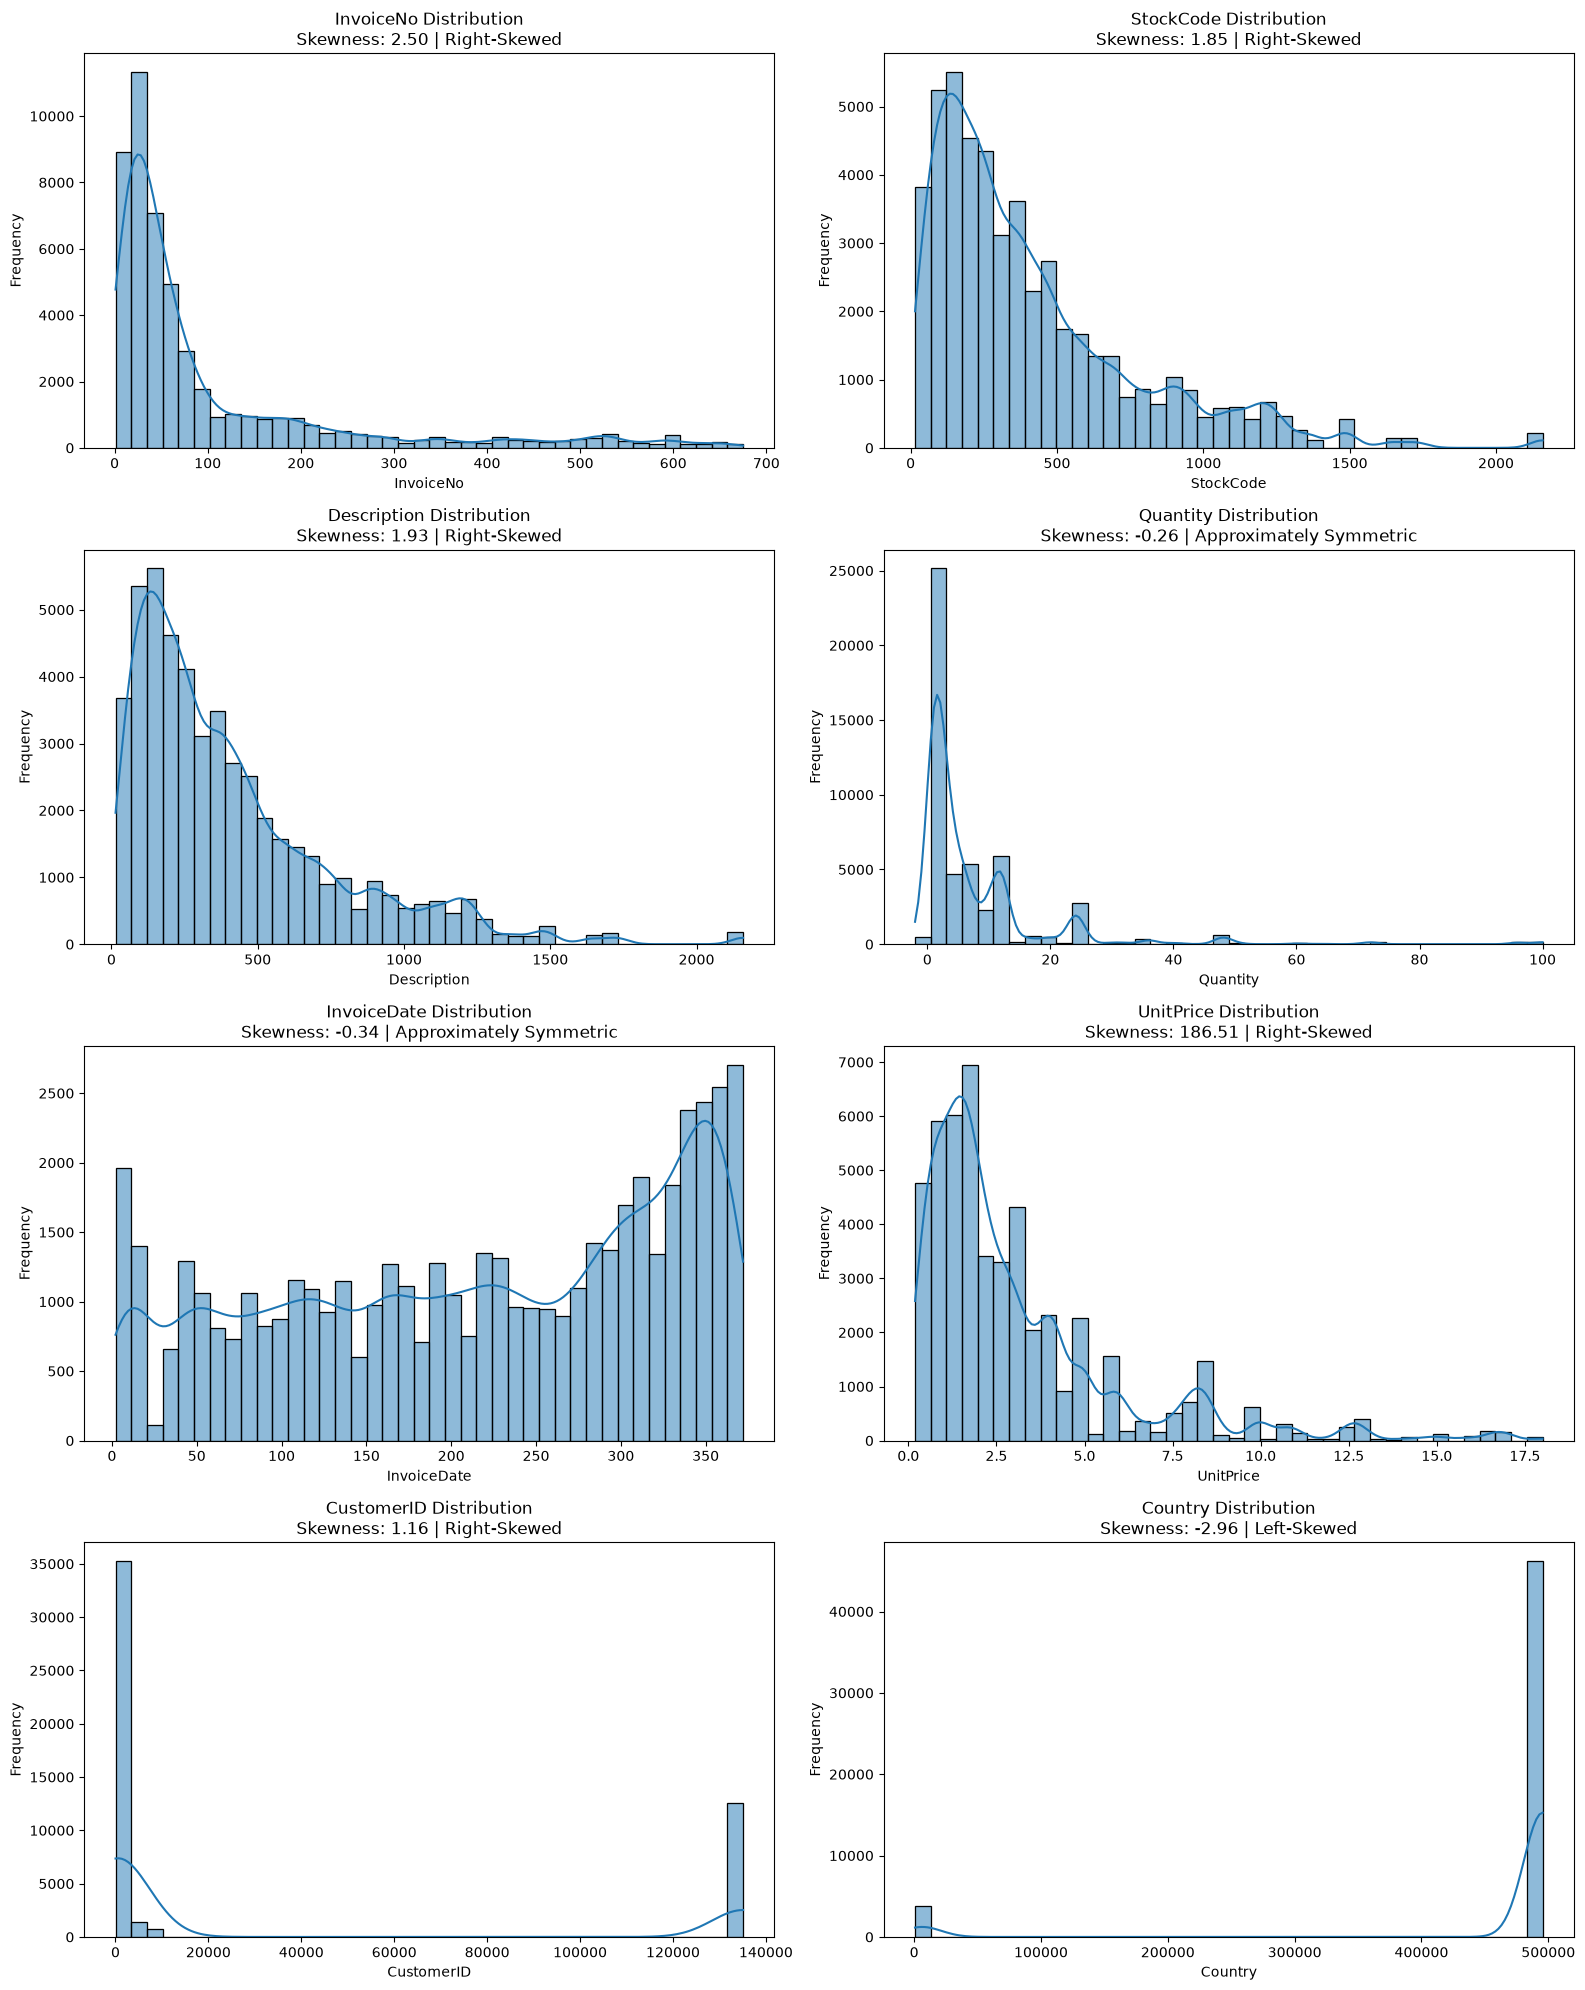

Skewness Summary for All 8 Columns:


,Column,Skewness,Distribution
0,InvoiceNo,2.50,Right-Skewed
1,StockCode,1.85,Right-Skewed
2,Description,1.93,Right-Skewed
3,Quantity,-0.26,Approximately Symmetric
4,InvoiceDate,-0.34,Approximately Symmetric
5,UnitPrice,186.51,Right-Skewed
6,CustomerID,1.16,Right-Skewed
7,Country,-2.96,Left-Skewed



Original Dataset Shape: (541909, 8)
Encoded Dataset Shape: (541909, 8)


In [10]:

# Distribution Analysis for All 8 Columns
fig, axes = plt.subplots(4, 2, figsize=(16, 20))

skewness_results = []

for ax, col in zip(axes.flat, df_encoded.columns):

    # Use Encoded / Numerical Data
    data = df_encoded[col].dropna()

    # Calculate Skewness Using Full Data
    skewness = data.skew()

    # Classify Skewness
    if skewness > 0.5:
        distribution = "Right-Skewed"
    elif skewness < -0.5:
        distribution = "Left-Skewed"
    else:
        distribution = "Approximately Symmetric"

    skewness_results.append({
        "Column": col,
        "Skewness": skewness,
        "Distribution": distribution
    })

    # Limit Visualization to P1-P99
    lower = data.quantile(0.01)
    upper = data.quantile(0.99)

    plot_data = data[data.between(lower, upper)]

    # Sample for Faster Visualization
    if len(plot_data) > 50000:
        plot_data = plot_data.sample(
            n=50000,
            random_state=42
        )

    # Histogram + KDE
    sns.histplot(
        plot_data,
        bins=40,
        kde=True,
        ax=ax
    )

    ax.set_title(
        f"{col} Distribution\n"
        f"Skewness: {skewness:.2f} | {distribution}"
    )

    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# Skewness Summary
skewness_summary = pd.DataFrame(skewness_results)

print("Skewness Summary for All 8 Columns:")
display(skewness_summary.round(2))

# Dataset Validation
print("\nOriginal Dataset Shape:", df.shape)
print("Encoded Dataset Shape:", df_encoded.shape)



### Key Insights & Recommendations

Distribution Analysis menunjukkan UnitPrice sangat right-skewed (186.51), sedangkan Quantity relatif simetris berdasarkan skewness (-0.26), meskipun dipengaruhi nilai ekstrem. Distribusi frekuensi produk dan pelanggan juga tidak merata, menunjukkan adanya perbedaan aktivitas pembelian. Perusahaan disarankan mempertahankan transaksi ekstrem yang valid serta menerapkan RFM Segmentation untuk mengidentifikasi pelanggan bernilai tinggi dan menyusun strategi retention yang lebih tepat sasaran.



## 8. RFM Data Cleaning


In [11]:

# Create RFM Dataset
df_rfm = df.copy()

# Convert InvoiceDate
df_rfm["InvoiceDate"] = pd.to_datetime(
    df_rfm["InvoiceDate"],
    errors="coerce"
)

# Standardize StockCode for Filtering
stock = df_rfm["StockCode"].astype(str).str.strip().str.upper()

# Known Non-Product Transaction Codes
non_product_codes = [
    "POST", "DOT", "C2",
    "M", "B", "BANK CHARGES",
    "AMAZONFEE", "S"
]

# Define Valid RFM Transactions
valid_rfm = (
    df_rfm["CustomerID"].notna() &
    df_rfm["InvoiceDate"].notna() &
    (df_rfm["Quantity"] > 0) &
    (df_rfm["UnitPrice"] > 0) &
    ~df_rfm["InvoiceNo"].astype(str).str.upper().str.startswith("C") &
    ~stock.isin(non_product_codes) &
    ~stock.str.startswith("GIFT_")
)

# Apply Cleaning
df_rfm = df_rfm.loc[valid_rfm].copy()

# Cleaning Summary
print("Original Rows:", len(df))
print("RFM Valid Rows:", len(df_rfm))
print("Rows Excluded:", len(df) - len(df_rfm))

print("\nUnique Customers:", df_rfm["CustomerID"].nunique())
print("Unique Invoices:", df_rfm["InvoiceNo"].nunique())

print("\nRemaining Missing Values:")
display(df_rfm.isnull().sum())

print("\nRemaining Duplicates:")
print(df_rfm.duplicated().sum())

print("\nDataset Shape:", df_rfm.shape)


Original Rows: 541909
RFM Valid Rows: 396340
Rows Excluded: 145569

Unique Customers: 4334
Unique Invoices: 18402

Remaining Missing Values:


InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


Remaining Duplicates:
5187

Dataset Shape: (396340, 8)



### Key Insights & Recommendations

Data Cleaning menghasilkan 396,340 baris transaksi valid (73.14%) dari 541,909 baris awal, mencakup 4,334 pelanggan dan 18,402 invoice unik. Sebanyak 26.86% baris dikeluarkan karena tidak memenuhi kriteria RFM, terutama terkait identitas pelanggan dan validitas transaksi. Perusahaan disarankan meningkatkan kualitas pencatatan pelanggan serta standardisasi transaksi agar analisis customer value dan strategi retention lebih akurat.



## 9. RFM Feature Engineering


In [12]:

# Create Revenue Feature
df_rfm["Revenue"] = (
    df_rfm["Quantity"] * df_rfm["UnitPrice"]
)

# Create Date Features
df_rfm["PurchaseDate"] = df_rfm["InvoiceDate"].dt.normalize()

df_rfm["YearMonth"] = (
    df_rfm["InvoiceDate"]
    .dt.to_period("M")
    .astype(str)
)

# Preview Engineered Features
print("Feature Engineering Preview:")

display(
    df_rfm[
        ["CustomerID", "InvoiceNo", "InvoiceDate",
         "PurchaseDate", "YearMonth",
         "Quantity", "UnitPrice", "Revenue"]
    ].head(10)
)

# Revenue Summary
print("\nRevenue Descriptive Statistics:")
display(df_rfm["Revenue"].describe())

# Date Range
print("\nEarliest Transaction:", df_rfm["PurchaseDate"].min())
print("Latest Transaction:", df_rfm["PurchaseDate"].max())

# Feature Validation
print("\nMissing Values in New Features:")
display(
    df_rfm[
        ["Revenue", "PurchaseDate", "YearMonth"]
    ].isnull().sum()
)

print("\nDataset Shape:", df_rfm.shape)


Feature Engineering Preview:


,CustomerID,InvoiceNo,InvoiceDate,PurchaseDate,YearMonth,Quantity,UnitPrice,Revenue
0,17850.0,536365,2010-12-01 08:26:00,2010-12-01,2010-12,6,2.55,15.30
1,17850.0,536365,2010-12-01 08:26:00,2010-12-01,2010-12,6,3.39,20.34
2,17850.0,536365,2010-12-01 08:26:00,2010-12-01,2010-12,8,2.75,22.00
3,17850.0,536365,2010-12-01 08:26:00,2010-12-01,2010-12,6,3.39,20.34
4,17850.0,536365,2010-12-01 08:26:00,2010-12-01,2010-12,6,3.39,20.34
5,17850.0,536365,2010-12-01 08:26:00,2010-12-01,2010-12,2,7.65,15.30
6,17850.0,536365,2010-12-01 08:26:00,2010-12-01,2010-12,6,4.25,25.50
7,17850.0,536366,2010-12-01 08:28:00,2010-12-01,2010-12,6,1.85,11.10
8,17850.0,536366,2010-12-01 08:28:00,2010-12-01,2010-12,6,1.85,11.10
9,13047.0,536367,2010-12-01 08:34:00,2010-12-01,2010-12,32,1.69,54.08



Revenue Descriptive Statistics:


count    396340.000000
mean         22.104927
std         308.897958
min           0.001000
25%           4.680000
50%          11.800000
75%          19.800000
max      168469.600000
Name: Revenue, dtype: float64


Earliest Transaction: 2010-12-01 00:00:00
Latest Transaction: 2011-12-09 00:00:00

Missing Values in New Features:


Revenue         0
PurchaseDate    0
YearMonth       0
dtype: int64


Dataset Shape: (396340, 11)



### Key Insights & Recommendations

Feature Engineering menghasilkan 3 kolom baru, yaitu Revenue, PurchaseDate, dan YearMonth, tanpa missing values. Revenue memiliki rata-rata £22.10 dan median £11.80, dengan nilai maksimum £168,469.60, menunjukkan adanya transaksi bernilai ekstrem. Perusahaan disarankan menggunakan fitur ini untuk menganalisis pola pembelian dan menghitung customer value, serta memperhitungkan retur agar Monetary dalam RFM Analysis lebih representatif.



## 10. Descriptive Statistics After Cleaning


In [13]:

# Numerical Descriptive Statistics
numerical_cols = ["Quantity", "UnitPrice", "Revenue"]

print("Numerical Descriptive Statistics:")

display(
    df_rfm[numerical_cols]
    .describe()
    .T
)

# Additional Statistical Measures
additional_stats = pd.DataFrame({
    "Median": df_rfm[numerical_cols].median(),
    "Variance": df_rfm[numerical_cols].var(),
    "Skewness": df_rfm[numerical_cols].skew(),
    "Kurtosis": df_rfm[numerical_cols].kurt()
})

print("\nAdditional Statistical Measures:")
display(additional_stats.round(2))

# Categorical Descriptive Statistics
categorical_cols = [
    "InvoiceNo", "StockCode",
    "Description", "Country"
]

print("\nCategorical Descriptive Statistics:")

display(
    df_rfm[categorical_cols]
    .describe()
    .T
)

# Dataset Summary
print("\nDataset Shape:", df_rfm.shape)
print("Unique Customers:", df_rfm["CustomerID"].nunique())
print("Unique Invoices:", df_rfm["InvoiceNo"].nunique())


Numerical Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
Quantity,396340.0,13.012456,179.640568,1.000,2.00,6.00,12.00,80995.0
UnitPrice,396340.0,2.868200,4.264654,0.001,1.25,1.95,3.75,649.5
Revenue,396340.0,22.104927,308.897958,0.001,4.68,11.80,19.80,168469.6



Additional Statistical Measures:


,Median,Variance,Skewness,Kurtosis
Quantity,6.00,32270.73,409.37,177653.38
UnitPrice,1.95,18.19,35.73,3482.95
Revenue,11.80,95417.95,453.89,233582.55



Categorical Descriptive Statistics:


,count,unique,top,freq
InvoiceNo,396340,18402,576339,541
StockCode,396340,3660,85123A,2035
Description,396340,3872,WHITE HANGING HEART T-LIGHT HOLDER,2028
Country,396340,37,United Kingdom,353988



Dataset Shape: (396340, 11)
Unique Customers: 4334
Unique Invoices: 18402



### Key Insights & Recommendations

Descriptive Statistics menunjukkan Quantity memiliki rata-rata 13.01 unit dan median 6 unit, sedangkan Revenue memiliki rata-rata £22.10 dan median £11.80. Skewness yang sangat tinggi pada Quantity (409.37), UnitPrice (35.73), dan Revenue (453.89) menunjukkan distribusi sangat right-skewed akibat nilai ekstrem. Perusahaan disarankan menggunakan median dan quantile-based scoring dalam RFM Analysis agar segmentasi pelanggan tidak terlalu dipengaruhi transaksi bernilai ekstrem.



## 11. Final Data Quality Validation


In [14]:

# Final Data Quality Checks
validation = pd.DataFrame({
    "Check": [
        "Missing Values",
        "Duplicate Rows",
        "Invalid CustomerID",
        "Invalid InvoiceDate",
        "Quantity <= 0",
        "UnitPrice <= 0",
        "Revenue <= 0",
        "Cancelled Invoice"
    ],
    "Count": [
        df_rfm.isna().sum().sum(),
        df_rfm.duplicated().sum(),
        df_rfm["CustomerID"].isna().sum(),
        df_rfm["InvoiceDate"].isna().sum(),
        (df_rfm["Quantity"] <= 0).sum(),
        (df_rfm["UnitPrice"] <= 0).sum(),
        (df_rfm["Revenue"] <= 0).sum(),
        df_rfm["InvoiceNo"].astype(str).str.startswith("C").sum()
    ]
})

validation["Percentage (%)"] = (
    validation["Count"] / len(df_rfm) * 100
).round(2)

print("Final Data Quality Summary:")
display(validation)

# Top 10 Highest Revenue Transactions
top_revenue = df_rfm.nlargest(10, "Revenue").copy()

print("\nTop 10 Highest Revenue Transactions:")
display(
    top_revenue[
        ["InvoiceNo", "CustomerID", "StockCode",
         "Description", "Quantity", "UnitPrice", "Revenue"]
    ]
)

# Search for Potential Matching Cancellations in Raw Data
cancelled = df[
    df["InvoiceNo"].astype(str).str.upper().str.startswith("C") &
    (df["Quantity"] < 0)
].copy()

cancelled["AbsQuantity"] = cancelled["Quantity"].abs()
top_revenue["AbsQuantity"] = top_revenue["Quantity"]

matches = top_revenue.merge(
    cancelled[
        ["InvoiceNo", "InvoiceDate", "CustomerID",
         "StockCode", "UnitPrice", "AbsQuantity"]
    ],
    on=["CustomerID", "StockCode", "UnitPrice", "AbsQuantity"],
    how="left",
    suffixes=("_Sale", "_Cancellation")
)

# Check whether cancellation occurred after purchase
matches["InvoiceDate_Cancellation"] = pd.to_datetime(
    matches["InvoiceDate_Cancellation"], errors="coerce"
)

matches["PotentialReversal"] = (
    matches["InvoiceNo_Cancellation"].notna() &
    (matches["InvoiceDate_Cancellation"] >=
     matches["InvoiceDate_Sale"])
)

print("\nPotential Matching Cancellations:")
display(
    matches.loc[matches["PotentialReversal"], [
        "InvoiceNo_Sale", "InvoiceNo_Cancellation",
        "CustomerID", "StockCode", "Quantity",
        "Revenue"
    ]]
)

print("\nDataset Shape:", df_rfm.shape)


Final Data Quality Summary:


,Check,Count,Percentage (%)
0,Missing Values,0,0.00
1,Duplicate Rows,5187,1.31
2,Invalid CustomerID,0,0.00
3,Invalid InvoiceDate,0,0.00
4,Quantity <= 0,0,0.00
5,UnitPrice <= 0,0,0.00
6,Revenue <= 0,0,0.00
7,Cancelled Invoice,0,0.00



Top 10 Highest Revenue Transactions:


,InvoiceNo,CustomerID,StockCode,Description,Quantity,UnitPrice,Revenue
540421,581483,16446.0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60
61619,541431,12346.0,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60
222680,556444,15098.0,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00
348325,567423,17450.0,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72
52711,540815,15749.0,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40
160546,550461,15749.0,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40
421601,573003,14646.0,23084,RABBIT NIGHT LIGHT,2400,2.08,4992.00
52709,540815,15749.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.55,4921.50
160542,550461,15749.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.40,4632.00
52772,540818,15749.0,48185,DOORMAT FAIRY CAKE,670,6.75,4522.50



Potential Matching Cancellations:


,InvoiceNo_Sale,InvoiceNo_Cancellation,CustomerID,StockCode,Quantity,Revenue
0,581483,C581484,16446.0,23843,80995,168469.6
1,541431,C541433,12346.0,23166,74215,77183.6
4,540815,C550456,15749.0,21108,3114,6539.4
7,540815,C550456,15749.0,85123A,1930,4921.5
9,540818,C550456,15749.0,48185,670,4522.5



Dataset Shape: (396340, 11)



### Key Insights & Recommendations

Final Data Quality Validation menunjukkan 396,340 baris transaksi telah memenuhi kriteria RFM tanpa missing values, tetapi masih terdapat 5,187 duplicate rows. Ditemukan pula transaksi bernilai tinggi, seperti £168,469.60, yang memiliki pasangan cancellation sehingga berpotensi melebihkan customer value. Perusahaan disarankan memperhitungkan retur dan pembatalan dalam Net Monetary serta meningkatkan validasi transaksi agar segmentasi RFM lebih akurat.



## 12. Net Monetary Validation


In [15]:

# Prepare Signed Product Transactions
df_net = df.copy()

df_net["InvoiceDate"] = pd.to_datetime(
    df_net["InvoiceDate"], errors="coerce"
)

stock = df_net["StockCode"].astype(str).str.strip().str.upper()

non_product_codes = [
    "POST", "DOT", "C2", "M", "B",
    "BANK CHARGES", "AMAZONFEE", "S"
]

# Include Purchases and Returns
valid_net = (
    df_net["CustomerID"].notna() &
    df_net["InvoiceDate"].notna() &
    (df_net["Quantity"] != 0) &
    (df_net["UnitPrice"] > 0) &
    ~stock.isin(non_product_codes) &
    ~stock.str.startswith("GIFT_")
)

df_net = df_net.loc[valid_net].copy()

# Signed Revenue: Positive Sales, Negative Returns
df_net["NetRevenue"] = (
    df_net["Quantity"] * df_net["UnitPrice"]
)

# Compare Gross and Net Monetary
gross = df_rfm.groupby("CustomerID")["Revenue"].sum()
net = df_net.groupby("CustomerID")["NetRevenue"].sum()

comparison = pd.DataFrame({
    "GrossMonetary": gross,
    "NetMonetary": net.reindex(gross.index)
})

comparison["ReturnAdjustment"] = (
    comparison["GrossMonetary"] -
    comparison["NetMonetary"]
)

print("Monetary Comparison:")
display(comparison.describe().round(2))

print("\nCustomers with Negative Net Monetary:")
print((comparison["NetMonetary"] < 0).sum())

print("\nTop 10 Customers by Gross Monetary:")
display(
    comparison.sort_values(
        "GrossMonetary", ascending=False
    ).head(10).round(2)
)

print("\nTotal Gross Monetary:", round(gross.sum(), 2))
print("Total Net Monetary:", round(net.sum(), 2))
print("Net Dataset Shape:", df_net.shape)


Monetary Comparison:


,GrossMonetary,NetMonetary,ReturnAdjustment
count,4334.00,4334.00,4334.00
mean,2021.47,1909.77,111.70
std,8907.50,8275.61,2861.20
min,3.75,-141.48,0.00
25%,305.56,298.40,0.00
50%,668.12,652.07,0.00
75%,1631.62,1604.26,14.85
max,279138.02,278571.62,168469.60



Customers with Negative Net Monetary:
2

Top 10 Customers by Gross Monetary:


,GrossMonetary,NetMonetary,ReturnAdjustment
CustomerID,,,
14646.0,279138.02,278571.62,566.40
18102.0,259657.30,259657.30,0.00
17450.0,194550.79,189650.73,4900.06
16446.0,168472.50,2.90,168469.60
14911.0,136275.72,128447.62,7828.10
12415.0,124564.53,123638.18,926.35
14156.0,116729.63,113855.32,2874.31
17511.0,91062.38,88138.20,2924.18
12346.0,77183.60,0.00,77183.60



Total Gross Monetary: 8761066.65
Total Net Monetary: 8273033.67
Net Dataset Shape: (404972, 9)



### Key Insights & Recommendations

Net Monetary Validation menunjukkan penurunan nilai pembelian dari £8,761,066.65 menjadi £8,273,033.67 setelah memperhitungkan retur dan cancellation, dengan selisih £488,032.98 (5.57%). Beberapa pelanggan bernilai tinggi mengalami penurunan Monetary yang signifikan akibat pembatalan transaksi. Perusahaan disarankan menggunakan Net Monetary dalam RFM Analysis agar penilaian customer value lebih representatif dan strategi retention lebih tepat sasaran.



## 13. Negative & Zero Net Monetary Investigation


In [16]:

# Identify Customers with Non-Positive Net Monetary
non_positive = comparison[
    comparison["NetMonetary"] <= 0
].copy()

print("Customers with Negative Monetary:",
      (comparison["NetMonetary"] < 0).sum())

print("Customers with Zero Monetary:",
      (comparison["NetMonetary"].abs() < 1e-8).sum())

print("\nNon-Positive Customer Summary:")
display(non_positive.round(2))

# Investigate Purchase and Return Activity
detail = df_net[
    df_net["CustomerID"].isin(non_positive.index)
].copy()

detail["TransactionFlow"] = np.where(
    detail["Quantity"] > 0,
    "PURCHASE",
    "RETURN"
)

print("\nTransaction Breakdown:")
display(
    detail.groupby(
        ["CustomerID", "TransactionFlow"]
    ).agg(
        TotalRows=("InvoiceNo", "size"),
        UniqueInvoices=("InvoiceNo", "nunique"),
        TotalValue=("NetRevenue", "sum")
    ).reset_index().round(2)
)


Customers with Negative Monetary: 2
Customers with Zero Monetary: 12

Non-Positive Customer Summary:


,GrossMonetary,NetMonetary,ReturnAdjustment
CustomerID,,,
12346.0,77183.60,0.00,77183.60
13364.0,134.96,0.00,134.96
13672.0,186.39,0.00,186.39
14557.0,788.38,0.00,788.38
14792.0,6.20,0.00,6.20
16546.0,787.15,-95.93,883.08
16878.0,13.30,0.00,13.30
17548.0,103.30,-141.48,244.78
18268.0,25.50,0.00,25.50



Transaction Breakdown:


,CustomerID,TransactionFlow,TotalRows,UniqueInvoices,TotalValue
0,12346.0,PURCHASE,1,1,77183.60
1,12346.0,RETURN,1,1,-77183.60
2,13364.0,PURCHASE,10,1,134.96
3,13364.0,RETURN,10,1,-134.96
4,13672.0,PURCHASE,6,2,186.39
5,13672.0,RETURN,9,3,-186.39
6,14557.0,PURCHASE,16,1,788.38
7,14557.0,RETURN,16,1,-788.38
8,14792.0,PURCHASE,2,1,6.20
9,14792.0,RETURN,2,1,-6.20



### Key Insights & Recommendations

Ditemukan 2 pelanggan dengan Net Monetary negatif (-£95.93 dan -£141.48) serta 12 pelanggan dengan nilai mendekati nol akibat penyesuaian retur dan cancellation. Kondisi ini menunjukkan bahwa nilai pembelian tinggi belum tentu mencerminkan kontribusi bersih pelanggan. Perusahaan disarankan mempertahankan pelanggan tersebut dalam RFM Analysis dengan Monetary Score terendah serta meningkatkan monitoring retur untuk mengevaluasi customer value secara akurat.



## 14. Monetary Precision & Validation


In [17]:

# Round Monetary Values to 2 Decimal Places
comparison["NetMonetaryRounded"] = (
    comparison["NetMonetary"].round(2)
)

# Classify Monetary Status
comparison["MonetaryStatus"] = np.select(
    [
        comparison["NetMonetaryRounded"] > 0,
        comparison["NetMonetaryRounded"] == 0,
        comparison["NetMonetaryRounded"] < 0
    ],
    [
        "POSITIVE",
        "ZERO",
        "NEGATIVE"
    ],
    default="REVIEW"
)

# Monetary Status Summary
print("Monetary Status Summary:")
display(
    comparison["MonetaryStatus"]
    .value_counts()
    .reset_index()
)

# Investigate Non-Positive Customers
print("\nNon-Positive Monetary Customers:")
display(
    comparison.loc[
        comparison["NetMonetaryRounded"] <= 0,
        ["GrossMonetary", "NetMonetary",
         "NetMonetaryRounded", "MonetaryStatus"]
    ].sort_values("NetMonetaryRounded")
)

# Check Final Customer Count
print("\nTotal Customers:", len(comparison))
print("Total Net Monetary: £",
      round(comparison["NetMonetaryRounded"].sum(), 2))


Monetary Status Summary:


,MonetaryStatus,count
0,POSITIVE,4320
1,ZERO,12
2,NEGATIVE,2



Non-Positive Monetary Customers:


,GrossMonetary,NetMonetary,NetMonetaryRounded,MonetaryStatus
CustomerID,,,,
17548.0,103.30,-1.414800e+02,-141.48,NEGATIVE
16546.0,787.15,-9.593000e+01,-95.93,NEGATIVE
12346.0,77183.60,0.000000e+00,0.00,ZERO
12454.0,3528.34,5.684342e-14,0.00,ZERO
13364.0,134.96,0.000000e+00,0.00,ZERO
13672.0,186.39,0.000000e+00,0.00,ZERO
12558.0,269.96,1.065814e-14,0.00,ZERO
12607.0,1579.51,3.552714e-15,0.00,ZERO
14557.0,788.38,0.000000e+00,0.00,ZERO



Total Customers: 4334
Total Net Monetary: £ 8276956.65



### Key Insights & Recommendations

Monetary Precision & Validation menunjukkan 4,320 pelanggan (99.68%) memiliki Net Monetary positif, sementara 12 pelanggan bernilai nol dan 2 pelanggan bernilai negatif. Pembulatan dua desimal memastikan konsistensi perhitungan dengan total Net Monetary sebesar £8,276,956.65. Perusahaan disarankan mempertahankan pelanggan dengan Monetary nol atau negatif pada segmen skor terendah agar evaluasi customer value dan strategi retention lebih akurat.



## 15. Net Monetary Reconciliation


In [18]:

# Customers with Valid Purchases
purchase_customers = df_rfm["CustomerID"].unique()

# Net Monetary for All Customers
net_all = df_net.groupby("CustomerID")["NetRevenue"].sum()

# Identify Return-Only Customers
return_only = net_all[
    ~net_all.index.isin(purchase_customers)
]

# Monetary Reconciliation
print("Customers with Valid Purchases:", len(purchase_customers))
print("Customers with Net Transactions:", len(net_all))
print("Return-Only Customers:", len(return_only))

print("\nMonetary Reconciliation:")
print("Total Net Monetary (All):",
      round(net_all.sum(), 2))

print("Net Monetary (RFM Customers):",
      round(comparison["NetMonetary"].sum(), 2))

print("Return-Only Monetary:",
      round(return_only.sum(), 2))

print("\nReconciliation Difference:")
print(round(
    comparison["NetMonetary"].sum()
    + return_only.sum()
    - net_all.sum(), 2
))

# Return-Only Customer Details
print("\nReturn-Only Customers:")
display(
    return_only
    .sort_values()
    .reset_index(name="NetMonetary")
    .round(2)
)


Customers with Valid Purchases: 4334
Customers with Net Transactions: 4362
Return-Only Customers: 28

Monetary Reconciliation:
Total Net Monetary (All): 8273033.67
Net Monetary (RFM Customers): 8276956.65
Return-Only Monetary: -3922.98

Reconciliation Difference:
0.0

Return-Only Customers:


,CustomerID,NetMonetary
0,14213.0,-1192.20
1,15823.0,-811.86
2,16742.0,-464.90
3,16252.0,-295.09
4,12666.0,-227.44
5,17307.0,-152.64
6,15728.0,-134.80
7,13958.0,-102.45
8,13829.0,-102.00
9,15638.0,-94.00



### Key Insights & Recommendations

Net Monetary Reconciliation mengidentifikasi 4,334 pelanggan dengan pembelian valid dan 28 Return-Only Customers dengan total nilai retur -£3,922.98. Hasil rekonsiliasi menunjukkan selisih £0, sehingga perhitungan Net Monetary sudah konsisten. Perusahaan disarankan menggunakan Net Monetary sebesar £8,276,956.65 dari pelanggan dengan pembelian valid untuk RFM Analysis, serta memantau pelanggan yang hanya melakukan retur secara terpisah.



## 16. Distribution Analysis After Cleaning


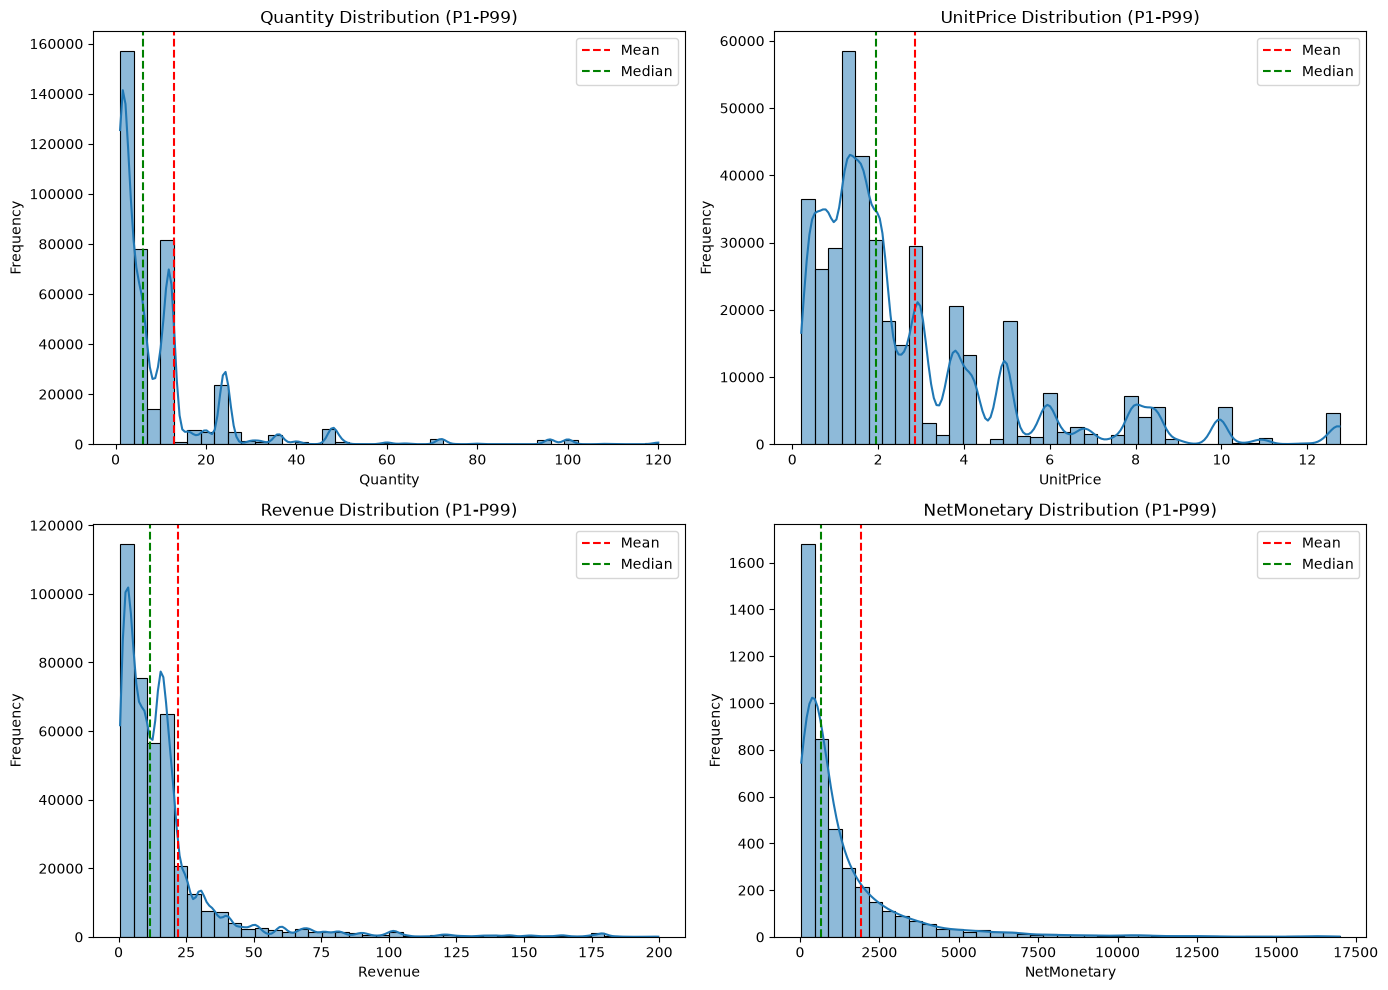

Distribution Statistics:


,Variable,Mean,Median,Std,Skewness,Kurtosis
0,Quantity,13.01,6.00,179.64,409.37,177653.38
1,UnitPrice,2.87,1.95,4.26,35.73,3482.95
2,Revenue,22.10,11.80,308.90,453.89,233582.55
3,NetMonetary,1909.77,652.07,8275.61,21.65,603.82


In [19]:

# Define Variables for Distribution Analysis
variables = {
    "Quantity": df_rfm["Quantity"],
    "UnitPrice": df_rfm["UnitPrice"],
    "Revenue": df_rfm["Revenue"],
    "NetMonetary": comparison["NetMonetaryRounded"]
}

# Create Distribution Plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (name, data) in zip(axes.flat, variables.items()):

    # Visualization Range (P1-P99)
    lower = data.quantile(0.01)
    upper = data.quantile(0.99)

    plot_data = data[data.between(lower, upper)]

    # Histogram and KDE
    sns.histplot(
        plot_data,
        bins=40,
        kde=True,
        ax=ax
    )

    # Mean and Median
    ax.axvline(
        data.mean(),
        color="red",
        linestyle="--",
        label="Mean"
    )

    ax.axvline(
        data.median(),
        color="green",
        linestyle="--",
        label="Median"
    )

    ax.set_title(f"{name} Distribution (P1-P99)")
    ax.set_xlabel(name)
    ax.set_ylabel("Frequency")
    ax.legend()

plt.tight_layout()
plt.show()

# Distribution Statistics
distribution_stats = pd.DataFrame({
    "Variable": list(variables.keys()),
    "Mean": [x.mean() for x in variables.values()],
    "Median": [x.median() for x in variables.values()],
    "Std": [x.std() for x in variables.values()],
    "Skewness": [x.skew() for x in variables.values()],
    "Kurtosis": [x.kurt() for x in variables.values()]
})

print("Distribution Statistics:")
display(distribution_stats.round(2))



### Key Insights & Recommendations

Distribution Analysis menunjukkan seluruh variabel sangat right-skewed, terutama Quantity (409.37), Revenue (453.89), dan NetMonetary (21.65). Rata-rata NetMonetary sebesar £1,909.77 jauh melebihi median £652.07, menunjukkan bahwa sebagian kecil pelanggan memberikan kontribusi pembelian yang tinggi. Perusahaan disarankan menggunakan RFM Segmentation berbasis quantile untuk mengidentifikasi pelanggan bernilai tinggi dan memprioritaskan strategi customer retention.


## Categorical Distribution Analysis

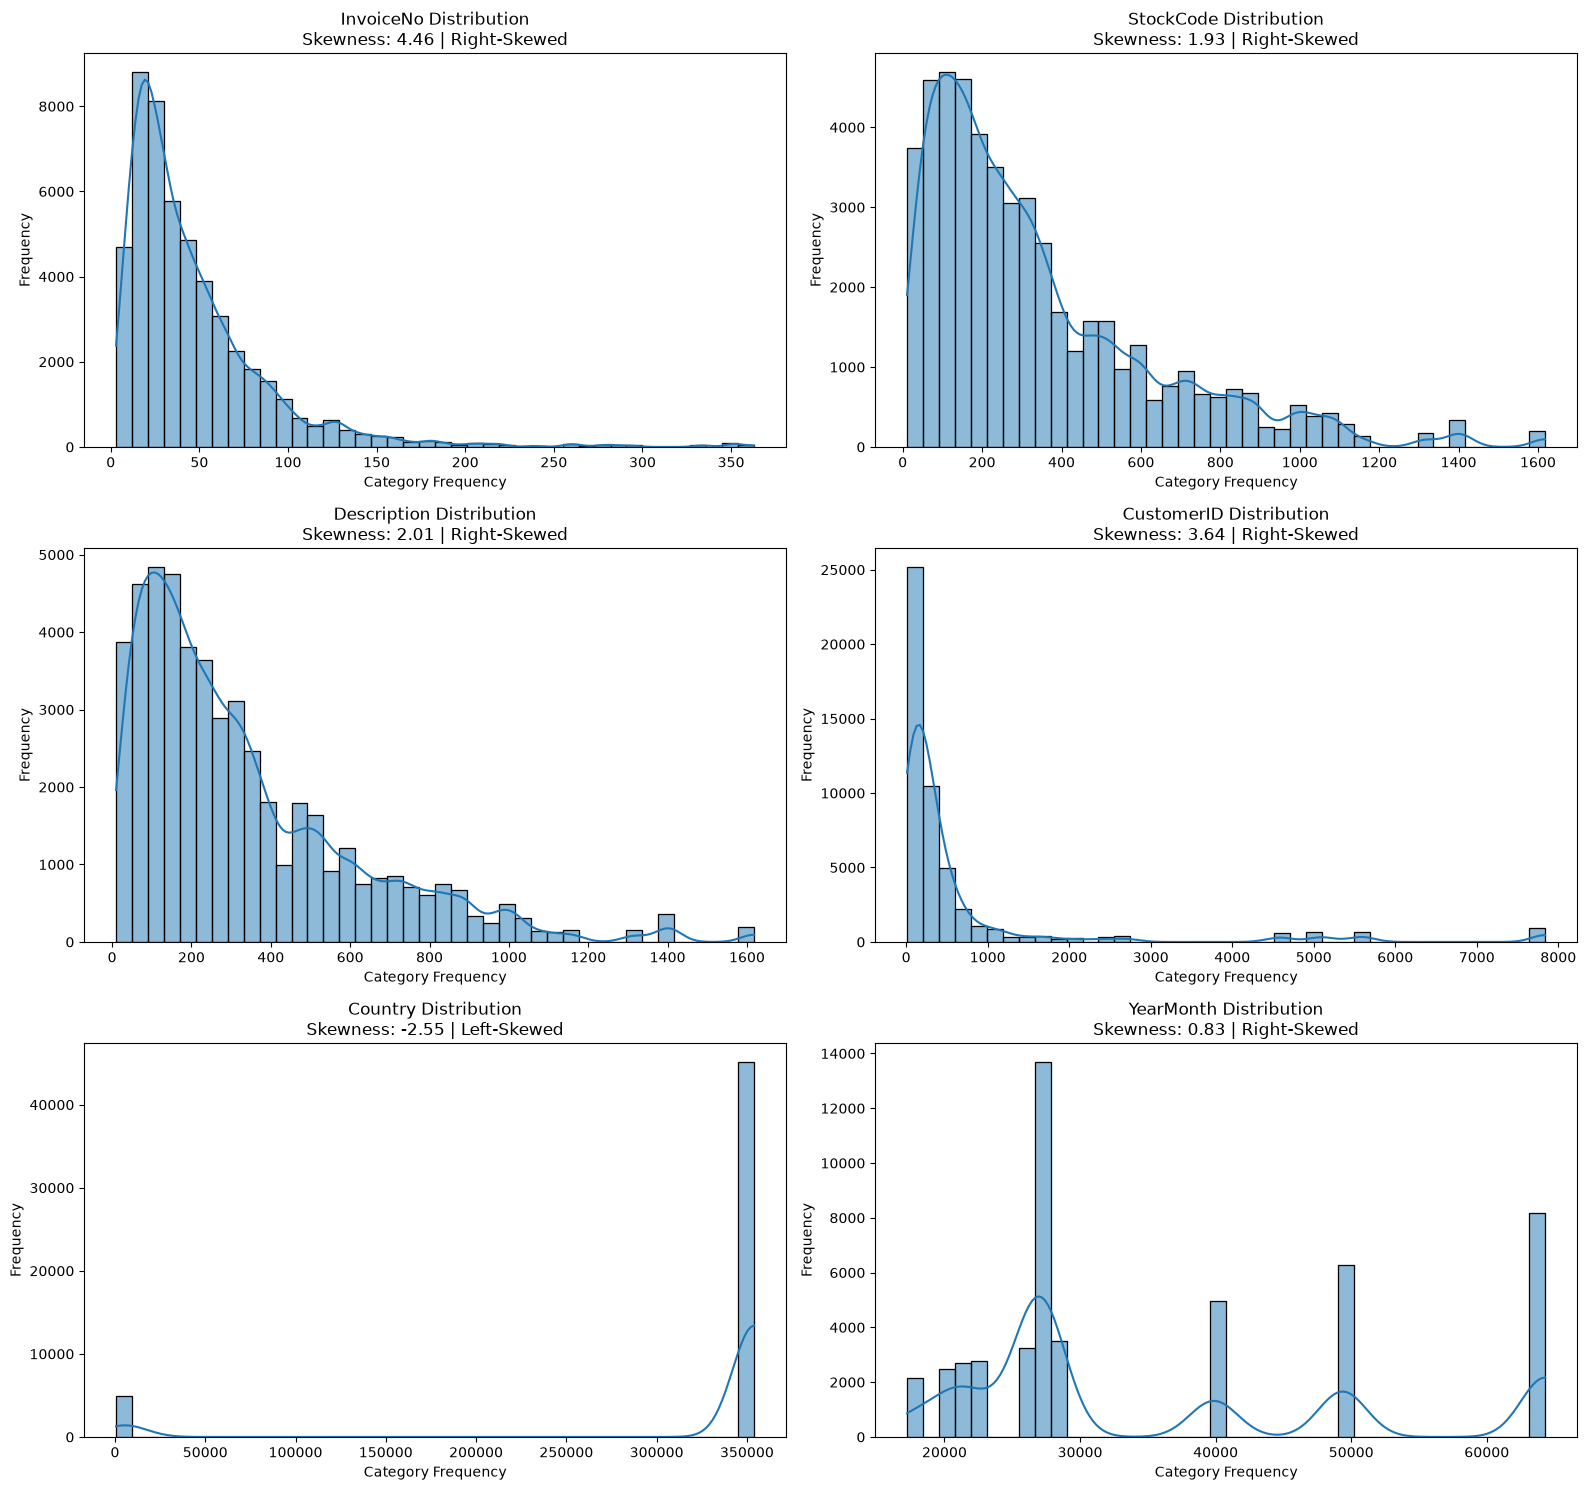

Categorical Distribution Statistics:


,Column,Skewness,Distribution
0,InvoiceNo,4.46,Right-Skewed
1,StockCode,1.93,Right-Skewed
2,Description,2.01,Right-Skewed
3,CustomerID,3.64,Right-Skewed
4,Country,-2.55,Left-Skewed
5,YearMonth,0.83,Right-Skewed



Original RFM Dataset: (396340, 11)
Encoded Dataset: (396340, 6)


In [20]:

# Categorical Columns After Cleaning
categorical_cols = [
    "InvoiceNo", "StockCode", "Description",
    "CustomerID", "Country", "YearMonth"
]

# Frequency Encoding
df_cat_encoded = pd.DataFrame(index=df_rfm.index)

for col in categorical_cols:
    values = df_rfm[col].astype("string").fillna("Missing")
    frequency = values.value_counts()
    df_cat_encoded[col] = values.map(frequency).astype(int)

# Categorical Distribution Visualization
fig, axes = plt.subplots(3, 2, figsize=(16, 15))

skewness_results = []

for ax, col in zip(axes.flat, categorical_cols):

    data = df_cat_encoded[col]

    # Calculate Skewness Using Full Data
    skewness = data.skew()

    if skewness > 0.5:
        distribution = "Right-Skewed"
    elif skewness < -0.5:
        distribution = "Left-Skewed"
    else:
        distribution = "Approximately Symmetric"

    skewness_results.append({
        "Column": col,
        "Skewness": skewness,
        "Distribution": distribution
    })

    # Visualization Range P1-P99
    lower = data.quantile(0.01)
    upper = data.quantile(0.99)

    plot_data = data[data.between(lower, upper)]

    # Sample for Faster Visualization
    if len(plot_data) > 50000:
        plot_data = plot_data.sample(
            n=50000,
            random_state=42
        )

    # Histogram + KDE
    sns.histplot(
        plot_data,
        bins=40,
        kde=True,
        ax=ax
    )

    ax.set_title(
        f"{col} Distribution\n"
        f"Skewness: {skewness:.2f} | {distribution}"
    )

    ax.set_xlabel("Category Frequency")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# Categorical Skewness Summary
print("Categorical Distribution Statistics:")
display(
    pd.DataFrame(skewness_results).round(2)
)

# Dataset Validation
print("\nOriginal RFM Dataset:", df_rfm.shape)
print("Encoded Dataset:", df_cat_encoded.shape)



### Key Insights & Recommendations

Categorical Distribution Analysis menunjukkan InvoiceNo (4.46), CustomerID (3.64), StockCode (1.93), Description (2.01), dan YearMonth (0.83) memiliki distribusi frekuensi right-skewed, sedangkan Country (-2.55) left-skewed akibat dominasi United Kingdom. Hasil ini menunjukkan aktivitas transaksi terkonsentrasi pada pelanggan, produk, dan periode tertentu. Perusahaan disarankan memprioritaskan pelanggan aktif melalui program loyalitas, mengoptimalkan stok produk populer, serta menggunakan RFM Segmentation untuk menyusun strategi customer retention yang lebih tepat sasaran.



## 17. D'Agostino-Pearson Normality Test & Q-Q Plot


D'Agostino-Pearson Normality Test:


,Variable,Sample Size,Statistic,P-Value,Normality
0,Quantity,396340,2357233.69,0.000e+00,Not Normal
1,UnitPrice,396340,1108065.13,0.000e+00,Not Normal
2,Revenue,396340,2421434.69,0.000e+00,Not Normal
3,NetMonetary,4334,9873.98,0.000e+00,Not Normal


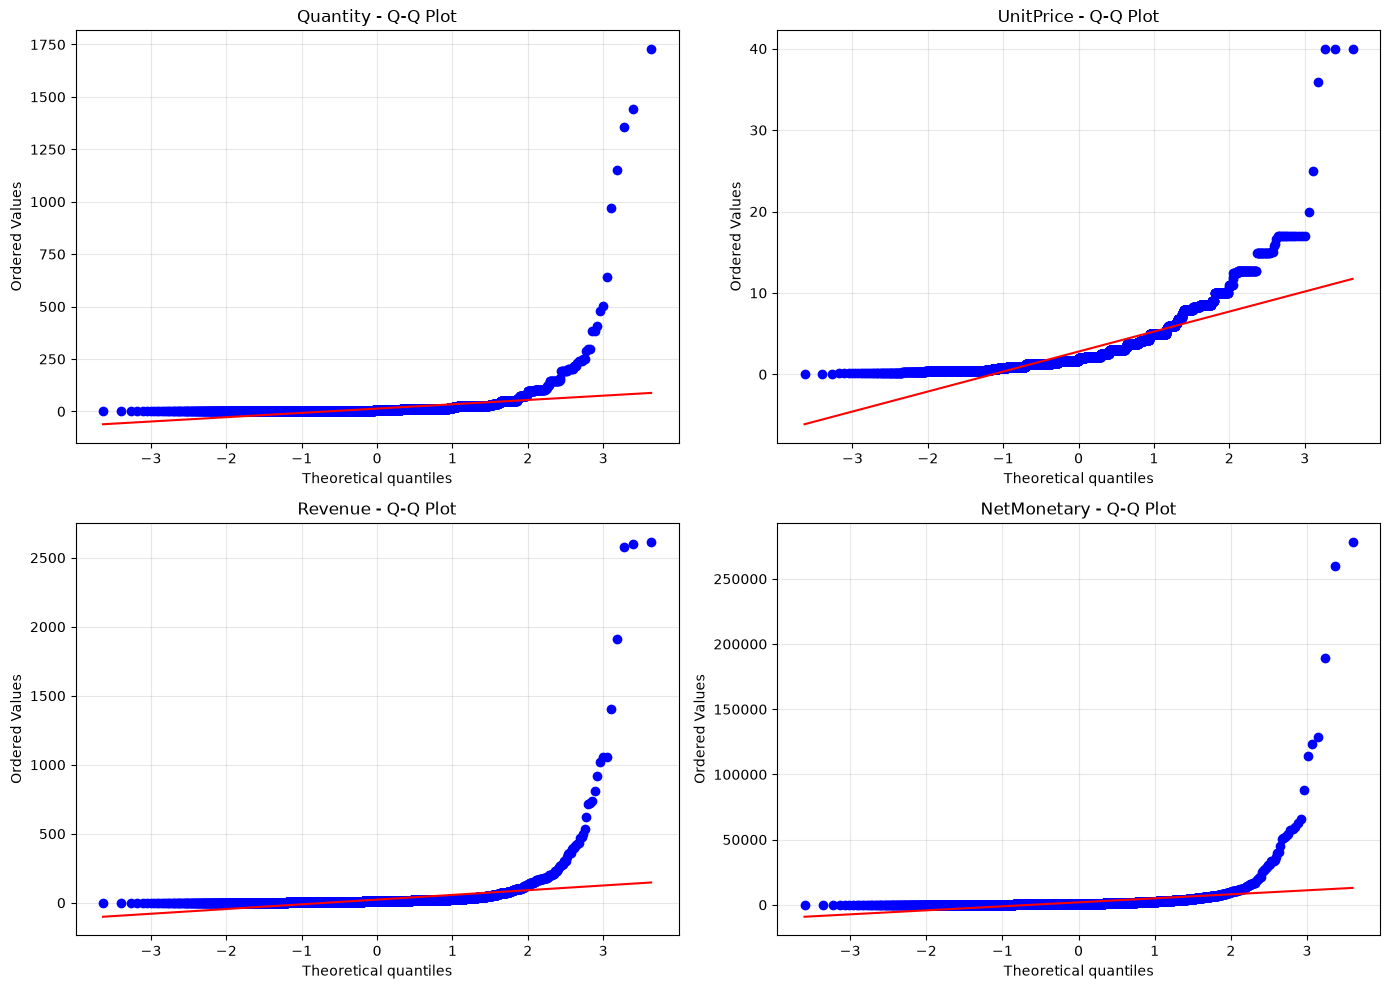

In [21]:

from scipy import stats

# Define Variables
variables = {
    "Quantity": df_rfm["Quantity"],
    "UnitPrice": df_rfm["UnitPrice"],
    "Revenue": df_rfm["Revenue"],
    "NetMonetary": comparison["NetMonetaryRounded"]
}

alpha = 0.05
normality_results = []

# Normality Test (Full Dataset)
for name, data in variables.items():

    data = data.dropna()

    statistic, p_value = stats.normaltest(data)

    normality_results.append({
        "Variable": name,
        "Sample Size": len(data),
        "Statistic": round(statistic, 2),
        "P-Value": f"{p_value:.3e}",
        "Normality": (
            "Normal" if p_value >= alpha
            else "Not Normal"
        )
    })

# Display Results
print("D'Agostino-Pearson Normality Test:")
display(pd.DataFrame(normality_results))

# Q-Q Plot
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (name, data) in zip(axes.flat, variables.items()):

    data = data.dropna()

    # Sample for Visualization Only
    if len(data) > 5000:
        plot_data = data.sample(
            n=5000,
            random_state=42
        )
    else:
        plot_data = data

    stats.probplot(
        plot_data,
        dist="norm",
        plot=ax
    )

    ax.set_title(f"{name} - Q-Q Plot")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



### Key Insights & Recommendations

D'Agostino-Pearson Normality Test menunjukkan Quantity, UnitPrice, Revenue, dan NetMonetary memiliki p-value < 0.05, sehingga seluruh variabel tidak berdistribusi normal. Q-Q Plot memperlihatkan penyimpangan signifikan akibat nilai ekstrem, terutama pada transaksi dan pelanggan bernilai tinggi. Perusahaan disarankan menggunakan median dan quantile-based RFM Scoring agar segmentasi pelanggan lebih representatif serta mendukung strategi customer retention yang tepat sasaran.



## 18. Pearson & Spearman Correlation Heatmap


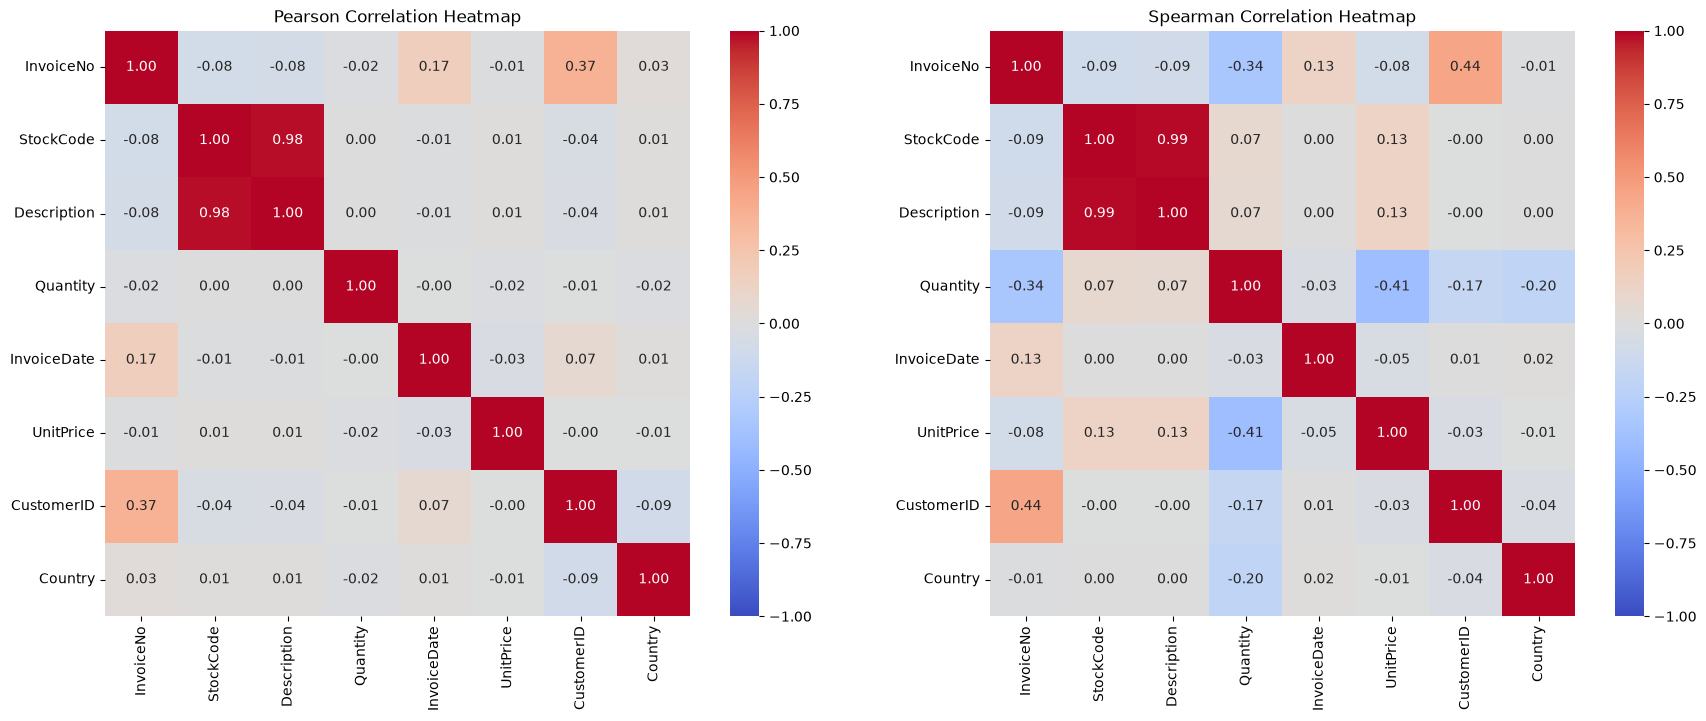

Pearson vs Spearman Correlation:


,Variable Pair,Pearson,Spearman
0,InvoiceNo vs StockCode,-0.0784,-0.0946
1,InvoiceNo vs Description,-0.0762,-0.0903
2,InvoiceNo vs Quantity,-0.0211,-0.3429
3,InvoiceNo vs InvoiceDate,0.1652,0.1325
4,InvoiceNo vs UnitPrice,-0.0092,-0.0804
5,InvoiceNo vs CustomerID,0.3683,0.4397
6,InvoiceNo vs Country,0.0275,-0.0093
7,StockCode vs Description,0.9836,0.9862
8,StockCode vs Quantity,0.0045,0.0704
9,StockCode vs InvoiceDate,-0.0106,0.0008



Correlation Dataset Shape: (396340, 8)
Original RFM Dataset Shape: (396340, 11)


In [22]:

# Select All 8 Original Columns
original_cols = [
    "InvoiceNo", "StockCode", "Description",
    "Quantity", "InvoiceDate", "UnitPrice",
    "CustomerID", "Country"
]

# Create Dataset for Correlation
df_corr = df_rfm[original_cols].copy()

# Frequency Encoding for Categorical Columns
categorical_cols = [
    "InvoiceNo", "StockCode", "Description",
    "CustomerID", "Country"
]

for col in categorical_cols:
    values = df_corr[col].astype("string")
    frequency = values.value_counts()
    df_corr[col] = values.map(frequency).astype(float)

# Convert InvoiceDate to Numeric (Days)
dates = pd.to_datetime(df_rfm["InvoiceDate"])

df_corr["InvoiceDate"] = (
    (dates - dates.min()).dt.total_seconds() / 86400
)

# Calculate Correlations
pearson_corr = df_corr.corr(method="pearson")
spearman_corr = df_corr.corr(method="spearman")

# Create Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[0]
)

axes[0].set_title("Pearson Correlation Heatmap")

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[1]
)

axes[1].set_title("Spearman Correlation Heatmap")

plt.tight_layout()
plt.show()

# Correlation Comparison
pairs = [
    (original_cols[i], original_cols[j])
    for i in range(len(original_cols))
    for j in range(i + 1, len(original_cols))
]

comparison_corr = pd.DataFrame([
    {
        "Variable Pair": f"{a} vs {b}",
        "Pearson": pearson_corr.loc[a, b],
        "Spearman": spearman_corr.loc[a, b]
    }
    for a, b in pairs
])

print("Pearson vs Spearman Correlation:")
display(
    comparison_corr.round(4)
)

# Dataset Validation
print("\nCorrelation Dataset Shape:", df_corr.shape)
print("Original RFM Dataset Shape:", df_rfm.shape)



### Key Insights & Recommendations

Correlation Heatmap pada 8 kolom menunjukkan hubungan sangat kuat antara frekuensi StockCode dan Description (Pearson 0.984), sedangkan Quantity dan UnitPrice memiliki korelasi negatif sedang (Spearman -0.406), mengindikasikan pembelian dalam jumlah besar cenderung memiliki harga per unit lebih rendah. Sebagian besar hubungan antarvariabel lainnya relatif lemah. Perusahaan disarankan mengevaluasi strategi volume pricing untuk pelanggan dengan pembelian besar serta menggunakan RFM Analysis untuk mengidentifikasi pelanggan bernilai tinggi. Korelasi variabel hasil Frequency Encoding perlu diinterpretasikan secara hati-hati karena tidak menunjukkan hubungan langsung antar kategori.



## 19. Monthly Revenue & Transaction Trend Analysis


Monthly Performance:


,YearMonth,TotalRevenue,TotalOrders,ActiveCustomers
0,2010-12,567490.72,1394,884
1,2011-01,564026.64,983,739
2,2011-02,443346.02,992,757
3,2011-03,584562.85,1312,973
4,2011-04,455266.91,1139,853
5,2011-05,660481.90,1544,1054
6,2011-06,654432.56,1390,990
7,2011-07,592731.90,1321,946
8,2011-08,636807.24,1267,933
9,2011-09,940900.81,1739,1259


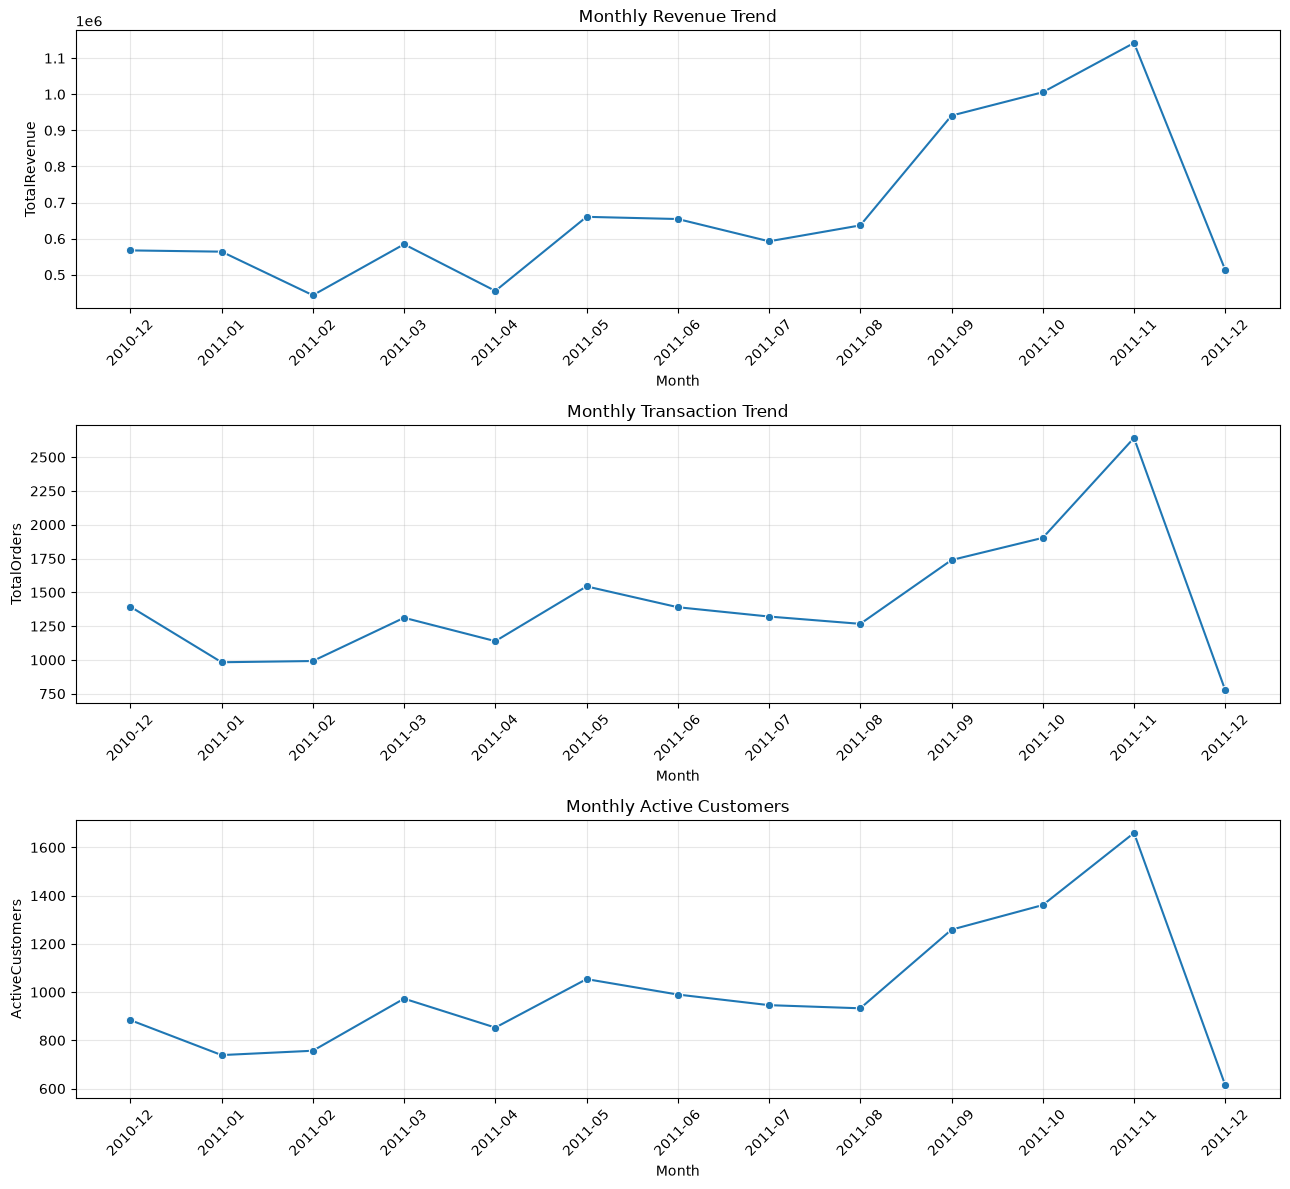

In [23]:

# Monthly Revenue and Transaction Analysis
monthly = (
    df_rfm.groupby("YearMonth")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        TotalOrders=("InvoiceNo", "nunique"),
        ActiveCustomers=("CustomerID", "nunique")
    )
    .reset_index()
    .sort_values("YearMonth")
)

# Monthly Summary
print("Monthly Performance:")
display(monthly.round(2))

# Visualizations
fig, axes = plt.subplots(3, 1, figsize=(13, 12))

metrics = [
    ("TotalRevenue", "Monthly Revenue Trend"),
    ("TotalOrders", "Monthly Transaction Trend"),
    ("ActiveCustomers", "Monthly Active Customers")
]

for ax, (col, title) in zip(axes, metrics):

    sns.lineplot(
        data=monthly,
        x="YearMonth",
        y=col,
        marker="o",
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Month")
    ax.set_ylabel(col)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



### Key Insights & Recommendations

Monthly Revenue Analysis menunjukkan tren pertumbuhan pada September–November 2011, dengan puncak revenue sebesar £1,142,145.77, sebanyak 2,642 orders, dan 1,660 pelanggan aktif pada November. Peningkatan ini menunjukkan pertumbuhan aktivitas pembelian yang sejalan dengan jumlah pelanggan aktif, meskipun pola musiman belum dapat dipastikan. Perusahaan disarankan mengoptimalkan stok dan kampanye pemasaran menjelang periode penjualan tinggi serta memperkuat program customer retention untuk mempertahankan pertumbuhan transaksi.



## 20. Customer Purchasing Behavior Analysis


Customer Purchasing Statistics:


,count,mean,std,min,25%,50%,75%,max
TotalOrders,4334.0,4.25,7.63,1.00,1.00,2.00,5.00,206.00
TotalQuantity,4334.0,1189.98,5042.96,1.00,160.00,379.00,991.75,196844.00
GrossPurchaseValue,4334.0,2021.47,8907.50,3.75,305.56,668.12,1631.62,279138.02
AOV,4334.0,417.01,1800.92,3.75,178.19,290.44,425.81,84236.25



Purchase Behavior Summary:


,PurchaseType,Customers,GrossPurchaseValue,Customer (%)
0,One-Time,1505,628969.67,34.73
1,Repeat,2829,8132096.98,65.27



Top 10 Customers by Order Frequency:


,CustomerID,TotalOrders,TotalQuantity,GrossPurchaseValue,AOV,PurchaseType
326,12748.0,206,25511,32317.32,156.880194,Repeat
1879,14911.0,198,80179,136275.72,688.261212,Repeat
4007,17841.0,124,23053,40967.72,330.384839,Repeat
562,13089.0,97,31070,58825.83,606.451856,Repeat
2176,15311.0,91,38194,60767.90,667.779121,Repeat
1661,14606.0,90,6214,12006.65,133.407222,Repeat
481,12971.0,86,9289,11189.91,130.115233,Repeat
1689,14646.0,72,196844,279138.02,3876.916944,Repeat
795,13408.0,62,16232,28117.04,453.500645,Repeat
2700,16029.0,62,40207,72882.09,1175.517581,Repeat


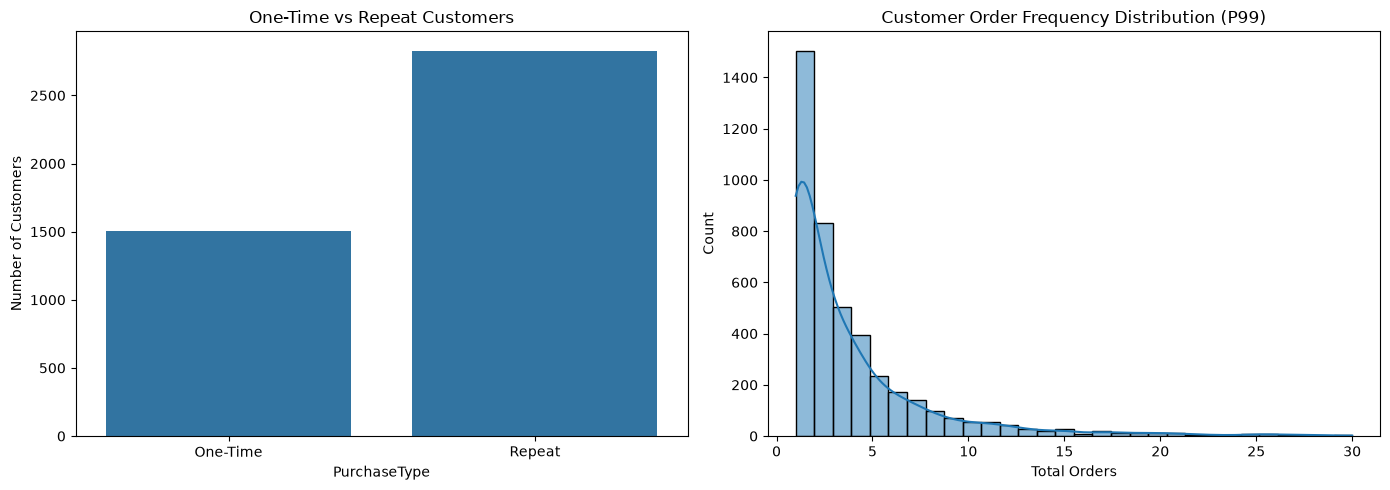

In [24]:

# Customer Purchasing Behavior
customer_behavior = (
    df_rfm.groupby("CustomerID")
    .agg(
        TotalOrders=("InvoiceNo", "nunique"),
        TotalQuantity=("Quantity", "sum"),
        GrossPurchaseValue=("Revenue", "sum")
    )
    .reset_index()
)

# Average Order Value
customer_behavior["AOV"] = (
    customer_behavior["GrossPurchaseValue"] /
    customer_behavior["TotalOrders"]
)

# Classify Purchase Behavior
customer_behavior["PurchaseType"] = np.where(
    customer_behavior["TotalOrders"] == 1,
    "One-Time",
    "Repeat"
)

# Descriptive Statistics
print("Customer Purchasing Statistics:")
display(
    customer_behavior[
        ["TotalOrders", "TotalQuantity",
         "GrossPurchaseValue", "AOV"]
    ].describe().T.round(2)
)

# Purchase Type Summary
purchase_summary = (
    customer_behavior.groupby("PurchaseType")
    .agg(
        Customers=("CustomerID", "nunique"),
        GrossPurchaseValue=("GrossPurchaseValue", "sum")
    )
    .reset_index()
)

purchase_summary["Customer (%)"] = (
    purchase_summary["Customers"] /
    len(customer_behavior) * 100
).round(2)

print("\nPurchase Behavior Summary:")
display(purchase_summary.round(2))

# Top 10 Customers by Order Frequency
print("\nTop 10 Customers by Order Frequency:")
display(
    customer_behavior.nlargest(10, "TotalOrders")
)

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=customer_behavior,
    x="PurchaseType",
    ax=axes[0]
)
axes[0].set_title("One-Time vs Repeat Customers")
axes[0].set_ylabel("Number of Customers")

# Limit visualization to P99
upper = customer_behavior["TotalOrders"].quantile(0.99)

sns.histplot(
    customer_behavior.loc[
        customer_behavior["TotalOrders"] <= upper,
        "TotalOrders"
    ],
    bins=30,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Customer Order Frequency Distribution (P99)")
axes[1].set_xlabel("Total Orders")

plt.tight_layout()
plt.show()



### Key Insights & Recommendations

Customer Purchasing Behavior Analysis menunjukkan 65.27% pelanggan merupakan Repeat Customers yang berkontribusi sebesar 92.82% terhadap Gross Purchase Value, sementara 34.73% hanya berbelanja sekali. Rata-rata pelanggan melakukan 4.25 orders, dengan median 2 orders, menunjukkan adanya perbedaan frekuensi pembelian yang cukup besar. Perusahaan disarankan memperkuat loyalty program untuk mempertahankan Repeat Customers serta memberikan insentif pembelian kedua bagi One-Time Customers untuk meningkatkan customer retention.



## 21. Customer Value & Revenue Concentration Analysis


Customer Revenue Concentration:


,Top Customers (%),Number of Customers,Net Monetary Contribution (%)
0,1,44,30.21
1,5,216,48.65
2,10,432,59.99
3,20,864,73.65



Top 10 Customers by Net Monetary:


,CustomerID,TotalOrders,AOV,NetMonetary
1689,14646.0,72,3876.92,278571.62
4197,18102.0,60,4327.62,259657.30
3725,17450.0,46,4229.36,189650.73
1879,14911.0,198,688.26,128447.62
55,12415.0,20,6228.23,123638.18
1333,14156.0,54,2161.66,113855.32
3768,17511.0,31,2937.50,88138.20
3174,16684.0,28,2380.48,65892.08
996,13694.0,50,1300.79,62677.10
2176,15311.0,91,667.78,59419.34


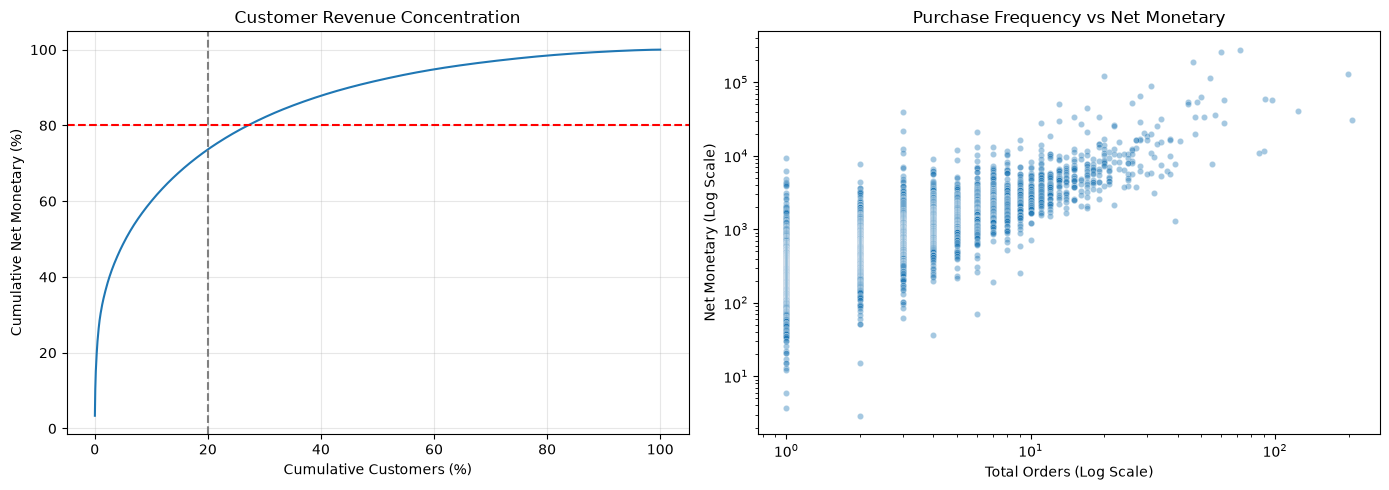

In [25]:

# Combine Customer Behavior with Net Monetary
customer_value = customer_behavior.copy()

customer_value["NetMonetary"] = (
    customer_value["CustomerID"]
    .map(comparison["NetMonetaryRounded"])
)

# Focus on Positive Net Monetary for Pareto
positive_customers = (
    customer_value[customer_value["NetMonetary"] > 0]
    .sort_values("NetMonetary", ascending=False)
    .copy()
)

# Calculate Cumulative Contribution
positive_customers["CumulativeRevenue (%)"] = (
    positive_customers["NetMonetary"].cumsum() /
    positive_customers["NetMonetary"].sum() * 100
)

positive_customers["CumulativeCustomers (%)"] = (
    np.arange(1, len(positive_customers) + 1) /
    len(positive_customers) * 100
)

# Top Customer Contribution
contribution = []

for pct in [1, 5, 10, 20]:
    n = int(np.ceil(len(positive_customers) * pct / 100))

    share = (
        positive_customers["NetMonetary"].head(n).sum() /
        positive_customers["NetMonetary"].sum() * 100
    )

    contribution.append({
        "Top Customers (%)": pct,
        "Number of Customers": n,
        "Net Monetary Contribution (%)": round(share, 2)
    })

print("Customer Revenue Concentration:")
display(pd.DataFrame(contribution))

print("\nTop 10 Customers by Net Monetary:")
display(
    positive_customers[
        ["CustomerID", "TotalOrders", "AOV", "NetMonetary"]
    ].head(10).round(2)
)

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pareto Curve
axes[0].plot(
    positive_customers["CumulativeCustomers (%)"],
    positive_customers["CumulativeRevenue (%)"]
)

axes[0].axhline(80, linestyle="--", color="red")
axes[0].axvline(20, linestyle="--", color="gray")

axes[0].set_title("Customer Revenue Concentration")
axes[0].set_xlabel("Cumulative Customers (%)")
axes[0].set_ylabel("Cumulative Net Monetary (%)")
axes[0].grid(alpha=0.3)

# Frequency vs Net Monetary
sns.scatterplot(
    data=positive_customers,
    x="TotalOrders",
    y="NetMonetary",
    alpha=0.4,
    s=20,
    ax=axes[1]
)

axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Purchase Frequency vs Net Monetary")
axes[1].set_xlabel("Total Orders (Log Scale)")
axes[1].set_ylabel("Net Monetary (Log Scale)")

plt.tight_layout()
plt.show()



### Key Insights & Recommendations

Customer Value Analysis menunjukkan bahwa 1% pelanggan teratas menyumbang 30.21% Net Monetary, sedangkan 20% pelanggan teratas berkontribusi sebesar 73.65%, menunjukkan konsentrasi revenue pada sebagian kecil pelanggan. Scatter plot juga memperlihatkan kecenderungan positif antara frekuensi pembelian dan Monetary. Perusahaan disarankan memprioritaskan pelanggan bernilai tinggi melalui program VIP dan personalized rewards, serta menggunakan RFM Segmentation untuk mengoptimalkan strategi customer retention.



## 22. RFM Feature Engineering


In [26]:

# Define Reference Date
reference_date = (
    df_rfm["PurchaseDate"].max() +
    pd.Timedelta(days=1)
)

print("Reference Date:", reference_date)

# Calculate Recency and Frequency
rfm = (
    df_rfm.groupby("CustomerID")
    .agg(
        LastPurchaseDate=("PurchaseDate", "max"),
        Frequency=("InvoiceNo", "nunique")
    )
)

# Calculate Recency
rfm["Recency"] = (
    reference_date - rfm["LastPurchaseDate"]
).dt.days

# Add Net Monetary
rfm["Monetary"] = (
    comparison["NetMonetaryRounded"]
    .reindex(rfm.index)
)

# Organize RFM Dataset
rfm = rfm[
    ["Recency", "Frequency", "Monetary"]
].reset_index()

# Preview
print("\nRFM Dataset Preview:")
display(rfm.head(10))

# Descriptive Statistics
print("\nRFM Descriptive Statistics:")
display(
    rfm[["Recency", "Frequency", "Monetary"]]
    .describe()
    .T
    .round(2)
)

# Validation
print("\nMissing Values:")
display(rfm.isnull().sum())

print("\nTotal Customers:", len(rfm))
print("Total Net Monetary: £", round(rfm["Monetary"].sum(), 2))
print("Dataset Shape:", rfm.shape)


Reference Date: 2011-12-10 00:00:00

RFM Dataset Preview:


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,0.00
1,12347.0,3,7,4310.00
2,12348.0,76,4,1437.24
3,12349.0,19,1,1457.55
4,12350.0,311,1,294.40
5,12352.0,37,7,1265.41
6,12353.0,205,1,89.00
7,12354.0,233,1,1079.40
8,12355.0,215,1,459.40
9,12356.0,23,3,2487.43



RFM Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
Recency,4334.0,93.23,100.18,1.00,18.0,51.00,143.00,374.00
Frequency,4334.0,4.25,7.63,1.00,1.0,2.00,5.00,206.00
Monetary,4334.0,1909.77,8275.61,-141.48,298.4,652.07,1604.26,278571.62



Missing Values:


CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64


Total Customers: 4334
Total Net Monetary: £ 8276956.65
Dataset Shape: (4334, 4)



### Key Insights & Recommendations

RFM Feature Engineering berhasil menghasilkan Recency, Frequency, dan Monetary untuk 4,334 pelanggan tanpa missing values. Median Recency sebesar 51 hari, Frequency 2 orders, dan Monetary £652.07 menunjukkan adanya variasi aktivitas serta nilai pembelian pelanggan. Perusahaan disarankan menggunakan RFM Scoring untuk mengidentifikasi pelanggan bernilai tinggi, pelanggan loyal, dan pelanggan yang berpotensi tidak aktif, sehingga strategi retention dapat lebih tepat sasaran.



## 23. RFM Scoring


In [27]:

# Recency: Lower is Better
rfm["R_Score"] = np.ceil(
    rfm["Recency"].rank(
        pct=True,
        ascending=False,
        method="average"
    ) * 5
).astype(int)

# Frequency: Higher is Better
rfm["F_Score"] = np.ceil(
    rfm["Frequency"].rank(
        pct=True,
        ascending=True,
        method="average"
    ) * 5
).astype(int)

# Monetary: Higher is Better
rfm["M_Score"] = np.ceil(
    rfm["Monetary"].rank(
        pct=True,
        ascending=True,
        method="average"
    ) * 5
).astype(int)

# Create RFM Code
rfm["RFM_Code"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

# Calculate Total Score
rfm["RFM_Total"] = (
    rfm["R_Score"] +
    rfm["F_Score"] +
    rfm["M_Score"]
)

# Preview
print("RFM Scoring Preview:")
display(rfm.head(10))

# Score Distribution
print("\nRFM Score Distribution:")
for col in ["R_Score", "F_Score", "M_Score"]:
    print(f"\n{col}:")
    display(rfm[col].value_counts().sort_index())

# Validation
print("\nMissing Values:", rfm.isnull().sum().sum())
print("Total Customers:", len(rfm))
print("Dataset Shape:", rfm.shape)


RFM Scoring Preview:


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Code,RFM_Total
0,12346.0,326,1,0.00,1,1,1,111,3
1,12347.0,3,7,4310.00,5,5,5,555,15
2,12348.0,76,4,1437.24,2,4,4,244,10
3,12349.0,19,1,1457.55,4,1,4,414,9
4,12350.0,311,1,294.40,1,1,2,112,4
5,12352.0,37,7,1265.41,3,5,4,354,12
6,12353.0,205,1,89.00,1,1,1,111,3
7,12354.0,233,1,1079.40,1,1,4,114,6
8,12355.0,215,1,459.40,1,1,2,112,4
9,12356.0,23,3,2487.43,4,3,5,435,12



RFM Score Distribution:

R_Score:


R_Score
1    863
2    861
3    865
4    880
5    865
Name: count, dtype: int64


F_Score:


F_Score
1    1505
3    1333
4     631
5     865
Name: count, dtype: int64


M_Score:


M_Score
1    866
2    867
3    867
4    867
5    867
Name: count, dtype: int64


Missing Values: 0
Total Customers: 4334
Dataset Shape: (4334, 9)



### Key Insights & Recommendations

RFM Scoring berhasil mengelompokkan 4,334 pelanggan menggunakan skor 1–5 berdasarkan Recency, Frequency, dan Monetary. Sebanyak 1,505 pelanggan memiliki Frequency Score 1, menunjukkan banyak pelanggan dengan frekuensi pembelian rendah. Perusahaan disarankan menggunakan kombinasi RFM Score untuk mengidentifikasi pelanggan loyal, bernilai tinggi, dan berisiko tidak aktif, serta mengembangkan strategi promosi dan retention yang sesuai dengan karakteristik setiap pelanggan.



## 24. RFM Customer Segmentation


In [28]:

# Define RFM Segmentation Rules
r = rfm["R_Score"]
f = rfm["F_Score"]
m = rfm["M_Score"]

conditions = [
    (r >= 4) & (f >= 4) & (m >= 4),
    (r <= 2) & (f >= 4) & (m >= 4),
    (r >= 3) & (f >= 4),
    (r >= 4) & (f >= 3),
    (r >= 4) & (f <= 2),
    (r <= 2) & (f >= 3),
    (r <= 2) & (f <= 2)
]

segments = [
    "Champions",
    "High-Value At Risk",
    "Loyal Customers",
    "Potential Loyalists",
    "Recent Low-Frequency",
    "At Risk",
    "Hibernating"
]

# Assign Customer Segments
rfm["Segment"] = np.select(
    conditions,
    segments,
    default="Needs Attention"
)

# Segment Summary
segment_summary = (
    rfm.groupby("Segment")
    .agg(
        Customers=("CustomerID", "count"),
        NetMonetary=("Monetary", "sum"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median")
    )
    .reset_index()
)

# Calculate Customer and Monetary Contribution
segment_summary["Customer (%)"] = (
    segment_summary["Customers"] / len(rfm) * 100
).round(2)

segment_summary["Monetary (%)"] = (
    segment_summary["NetMonetary"] /
    rfm["Monetary"].sum() * 100
).round(2)

# Display Results
print("RFM Customer Segmentation Summary:")
display(
    segment_summary.sort_values(
        "NetMonetary", ascending=False
    ).round(2)
)

# Validation
print("\nTotal Segmented Customers:",
      segment_summary["Customers"].sum())

print("Total Customers:", len(rfm))
print("Missing Segments:", rfm["Segment"].isna().sum())

print("\nFinal RFM Dataset Shape:", rfm.shape)


RFM Customer Segmentation Summary:


,Segment,Customers,NetMonetary,MedianRecency,MedianFrequency,MedianMonetary,Customer (%),Monetary (%)
1,Champions,910,5460625.18,11.0,8.0,2634.25,21.00,65.97
4,Loyal Customers,379,769378.76,41.0,5.0,1227.43,8.74,9.30
0,At Risk,614,515189.84,152.0,2.0,596.97,14.17,6.22
6,Potential Loyalists,484,407673.42,18.0,2.0,630.66,11.17,4.93
5,Needs Attention,599,370640.44,53.0,2.0,424.40,13.82,4.48
2,Hibernating,968,346536.32,233.0,1.0,248.26,22.34,4.19
3,High-Value At Risk,142,331347.73,104.0,5.0,1833.16,3.28,4.00
7,Recent Low-Frequency,238,75564.96,20.0,1.0,226.23,5.49,0.91



Total Segmented Customers: 4334
Total Customers: 4334
Missing Segments: 0

Final RFM Dataset Shape: (4334, 10)



### Key Insights & Recommendations

RFM Customer Segmentation berhasil membagi 4,334 pelanggan menjadi 8 segmen, dengan Champions mencakup 21% pelanggan tetapi menyumbang 65.97% Net Monetary. Sementara itu, Hibernating menjadi segmen terbesar (22.34%) dan terdapat 142 High-Value At Risk Customers. Perusahaan disarankan memprioritaskan VIP loyalty program untuk Champions, personalized win-back campaign bagi High-Value At Risk, serta reactivation campaign untuk pelanggan Hibernating guna meningkatkan customer retention.



## 25. Customer Segment Distribution & Revenue Contribution


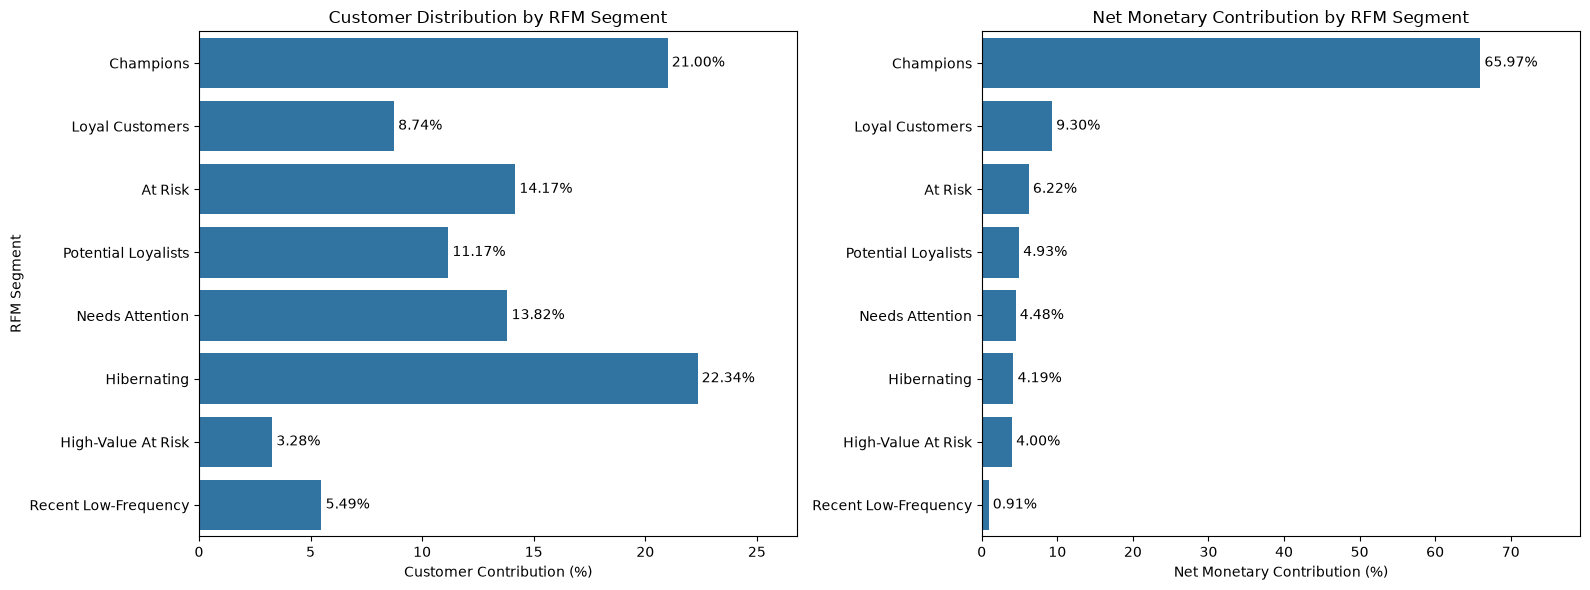

RFM Segment Performance:


,Segment,Customers,Customer (%),NetMonetary,Monetary (%)
1,Champions,910,21.00,5460625.18,65.97
4,Loyal Customers,379,8.74,769378.76,9.30
0,At Risk,614,14.17,515189.84,6.22
6,Potential Loyalists,484,11.17,407673.42,4.93
5,Needs Attention,599,13.82,370640.44,4.48
2,Hibernating,968,22.34,346536.32,4.19
3,High-Value At Risk,142,3.28,331347.73,4.00
7,Recent Low-Frequency,238,5.49,75564.96,0.91


In [29]:

# Prepare Segment Visualization Data
segment_viz = segment_summary.sort_values(
    "NetMonetary", ascending=False
).copy()

# Create Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Customer Distribution
sns.barplot(
    data=segment_viz,
    x="Customer (%)",
    y="Segment",
    ax=axes[0]
)

axes[0].set_title("Customer Distribution by RFM Segment")
axes[0].set_xlabel("Customer Contribution (%)")
axes[0].set_ylabel("RFM Segment")

# Monetary Contribution
sns.barplot(
    data=segment_viz,
    x="Monetary (%)",
    y="Segment",
    ax=axes[1]
)

axes[1].set_title("Net Monetary Contribution by RFM Segment")
axes[1].set_xlabel("Net Monetary Contribution (%)")
axes[1].set_ylabel("")

# Add Percentage Labels
for ax in axes:
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.2f%%",
            padding=3
        )

    ax.set_xlim(
        0,
        max(p.get_width()
            for p in ax.patches) * 1.2
    )

plt.tight_layout()
plt.show()

# Segment Performance Summary
print("RFM Segment Performance:")
display(
    segment_viz[
        ["Segment", "Customers", "Customer (%)",
         "NetMonetary", "Monetary (%)"]
    ].round(2)
)



### Key Insights & Recommendations

Customer Segment Analysis menunjukkan Champions mencakup 21% pelanggan tetapi berkontribusi 65.97% terhadap Net Monetary, sedangkan Hibernating menjadi segmen terbesar (22.34%) dengan kontribusi hanya 4.19%. Champions dan Loyal Customers secara gabungan menyumbang 75.27% Net Monetary, menunjukkan tingginya konsentrasi customer value. Perusahaan disarankan memprioritaskan program loyalitas untuk pelanggan bernilai tinggi dan menjalankan reactivation campaign yang efisien bagi pelanggan Hibernating.



## 26. RFM Segment Behavioral Analysis


RFM Segment Behavioral Summary:


,Segment,Customers,MedianRecency,MedianFrequency,MedianMonetary
1,Champions,910,11.0,8.0,2634.25
3,High-Value At Risk,142,104.0,5.0,1833.16
4,Loyal Customers,379,41.0,5.0,1227.43
6,Potential Loyalists,484,18.0,2.0,630.66
0,At Risk,614,152.0,2.0,596.97
5,Needs Attention,599,53.0,2.0,424.40
2,Hibernating,968,233.0,1.0,248.26
7,Recent Low-Frequency,238,20.0,1.0,226.23


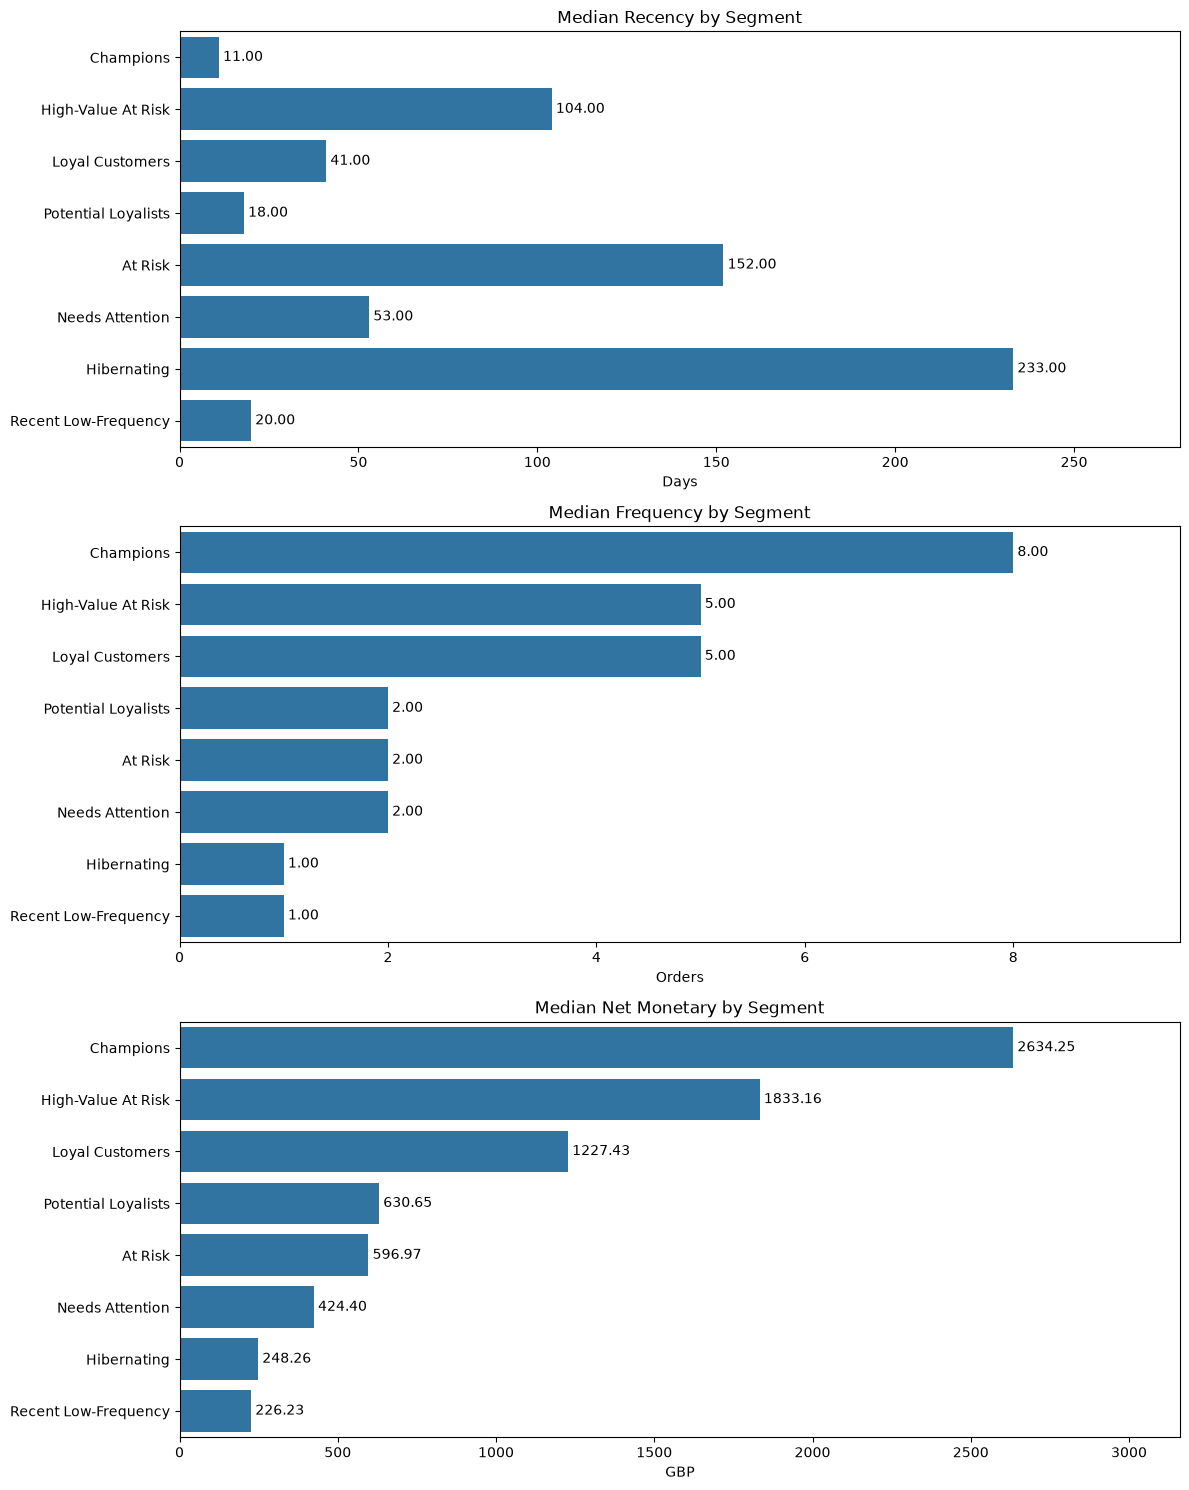

In [30]:

# Segment Behavioral Summary
segment_behavior = (
    rfm.groupby("Segment")
    .agg(
        Customers=("CustomerID", "count"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median")
    )
    .reset_index()
    .sort_values("MedianMonetary", ascending=False)
)

print("RFM Segment Behavioral Summary:")
display(segment_behavior.round(2))

# Visualizations
fig, axes = plt.subplots(3, 1, figsize=(12, 15))

metrics = [
    ("MedianRecency", "Median Recency by Segment", "Days"),
    ("MedianFrequency", "Median Frequency by Segment", "Orders"),
    ("MedianMonetary", "Median Net Monetary by Segment", "GBP")
]

for ax, (col, title, xlabel) in zip(axes, metrics):

    sns.barplot(
        data=segment_behavior,
        x=col,
        y="Segment",
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.2f",
            padding=3
        )

    ax.set_xlim(
        0,
        segment_behavior[col].max() * 1.2
    )

plt.tight_layout()
plt.show()



### Key Insights & Recommendations

RFM Segment Behavioral Analysis menunjukkan Champions memiliki median Recency 11 hari, Frequency 8 orders, dan Monetary £2,634.25, sedangkan High-Value At Risk memiliki Monetary £1,833.16 tetapi sudah tidak bertransaksi selama median 104 hari. Hibernating memiliki Recency tertinggi (233 hari) dengan Frequency hanya 1 order. Perusahaan disarankan mempertahankan Champions melalui VIP rewards, memprioritaskan win-back campaign untuk High-Value At Risk, dan menerapkan low-cost reactivation campaign bagi Hibernating Customers.



## 27. Customer Retention Prioritization & Action Plan


In [31]:

# Define Retention Priority
priority_map = {
    "Champions": "High",
    "High-Value At Risk": "Critical",
    "Loyal Customers": "High",
    "Potential Loyalists": "High",
    "At Risk": "Medium",
    "Needs Attention": "Medium",
    "Hibernating": "Low",
    "Recent Low-Frequency": "Medium"
}

# Define Recommended Actions
action_map = {
    "Champions": "VIP Rewards & Exclusive Benefits",
    "High-Value At Risk": "Personalized Win-Back Campaign",
    "Loyal Customers": "Loyalty & Referral Program",
    "Potential Loyalists": "Second Purchase Incentives",
    "At Risk": "Targeted Reactivation Campaign",
    "Needs Attention": "Personalized Product Recommendations",
    "Hibernating": "Low-Cost Re-engagement Campaign",
    "Recent Low-Frequency": "Welcome & Repeat Purchase Offers"
}

# Assign Priority and Recommended Actions
rfm["RetentionPriority"] = rfm["Segment"].map(priority_map)
rfm["RecommendedAction"] = rfm["Segment"].map(action_map)

# Create Action Plan Summary
action_plan = (
    rfm.groupby(
        ["Segment", "RetentionPriority", "RecommendedAction"]
    )
    .agg(
        Customers=("CustomerID", "count"),
        TotalMonetary=("Monetary", "sum"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median")
    )
    .reset_index()
)

# Monetary Contribution
action_plan["Monetary (%)"] = (
    action_plan["TotalMonetary"] /
    rfm["Monetary"].sum() * 100
).round(2)

# Sort by Business Priority
priority_order = {
    "Critical": 1,
    "High": 2,
    "Medium": 3,
    "Low": 4
}

action_plan["PriorityOrder"] = (
    action_plan["RetentionPriority"].map(priority_order)
)

action_plan = action_plan.sort_values(
    ["PriorityOrder", "TotalMonetary"],
    ascending=[True, False]
).drop(columns="PriorityOrder")

print("Customer Retention Action Plan:")
display(action_plan.round(2))

print("\nFinal RFM Dataset Shape:", rfm.shape)


Customer Retention Action Plan:


,Segment,RetentionPriority,RecommendedAction,Customers,TotalMonetary,MedianRecency,MedianFrequency,Monetary (%)
3,High-Value At Risk,Critical,Personalized Win-Back Campaign,142,331347.73,104.0,5.0,4.00
1,Champions,High,VIP Rewards & Exclusive Benefits,910,5460625.18,11.0,8.0,65.97
4,Loyal Customers,High,Loyalty & Referral Program,379,769378.76,41.0,5.0,9.30
6,Potential Loyalists,High,Second Purchase Incentives,484,407673.42,18.0,2.0,4.93
0,At Risk,Medium,Targeted Reactivation Campaign,614,515189.84,152.0,2.0,6.22
5,Needs Attention,Medium,Personalized Product Recommendations,599,370640.44,53.0,2.0,4.48
7,Recent Low-Frequency,Medium,Welcome & Repeat Purchase Offers,238,75564.96,20.0,1.0,0.91
2,Hibernating,Low,Low-Cost Re-engagement Campaign,968,346536.32,233.0,1.0,4.19



Final RFM Dataset Shape: (4334, 12)



### Key Insights & Recommendations

Customer Retention Analysis menetapkan 142 High-Value At Risk Customers sebagai prioritas Critical dengan kontribusi Net Monetary sebesar £331,347.73 (4%), sedangkan Champions menyumbang 65.97% dari total nilai pembelian bersih. Perusahaan disarankan menjalankan personalized win-back campaign untuk pelanggan berisiko, mempertahankan Champions melalui VIP rewards, serta memberikan insentif repeat purchase bagi Potential Loyalists untuk meningkatkan customer retention dan customer value.


## 28. Additional Data Validation & Sensitivity Analysis

### Data Format Standardization

In [32]:

# Create Standardized Dataset
df_standardized = df.copy()

# Standardize StockCode
df_standardized["StockCode"] = (
    df_standardized["StockCode"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Standardize Description
df_standardized["Description"] = (
    df_standardized["Description"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Compare Before and After
summary = pd.DataFrame({
    "Column": ["StockCode", "Description"],
    "Unique Before": [
        df[col].nunique()
        for col in ["StockCode", "Description"]
    ],
    "Unique After": [
        df_standardized[col].nunique()
        for col in ["StockCode", "Description"]
    ]
})

summary["Unique Reduced"] = (
    summary["Unique Before"] -
    summary["Unique After"]
)

print("Standardization Summary:")
display(summary)

# Duplicate Impact
print("\nDuplicates Before:", df.duplicated().sum())
print("Duplicates After:", df_standardized.duplicated().sum())

# Dataset Validation
print("\nOriginal Dataset:", df.shape)
print("Standardized Dataset:", df_standardized.shape)


Standardization Summary:


,Column,Unique Before,Unique After,Unique Reduced
0,StockCode,4070,3958,112
1,Description,4223,4194,29



Duplicates Before: 5268
Duplicates After: 5268

Original Dataset: (541909, 8)
Standardized Dataset: (541909, 8)



### Key Insights & Recommendations

Data Format Standardization mengurangi unique StockCode dari 4,070 menjadi 3,958 dan Description dari 4,223 menjadi 4,194 tanpa mengubah jumlah transaksi maupun 5,268 duplicate rows. Hasil ini menunjukkan bahwa perbedaan format dapat menyebabkan kategori produk terpecah, tetapi tidak memengaruhi jumlah duplikasi yang terdeteksi. Perusahaan disarankan menerapkan standardisasi otomatis pada database produk untuk meningkatkan konsistensi pencatatan dan akurasi analisis penjualan.


### Feature Engineering — Transaction Classification

In [33]:

# Create Classification Dataset
df_classified = df_standardized.copy()

invoice = df_classified["InvoiceNo"].astype(str).str.upper()
stock = df_classified["StockCode"].astype("string").fillna("")
desc = df_classified["Description"].astype("string").fillna("")

qty = df_classified["Quantity"]
price = df_classified["UnitPrice"]

# 1. Classify Transaction Flow
df_classified["TransactionFlow"] = np.select(
    [
        invoice.str.startswith("C") & (qty < 0),
        (qty < 0) & (price == 0),
        qty < 0,
        price < 0,
        (qty > 0) & (price == 0),
        (qty > 0) & (price > 0)
    ],
    [
        "CANCELLATION_OR_RETURN",
        "STOCK_OUTFLOW_REVIEW",
        "NEGATIVE_TRANSACTION_REVIEW",
        "NEGATIVE_PRICE_REVIEW",
        "ZERO_VALUE_ENTRY",
        "POSITIVE_VALUE_ENTRY"
    ],
    default="OTHER_REVIEW"
)

# 2. Identify Damage and Stock Check Descriptions
damage = desc.str.contains(
    r"\b(?:DAMAGED?|DAMAGES|FAULTY|BROKEN|CRUSHED|SMASHED|UNSALEABLE|DESTROYED|THROWN AWAY)\b",
    regex=True
)

stock_check = desc.str.contains(
    r"\b(?:CHECK|FOUND|MISSING|ADJUSTMENT|INCORRECT STOCK ENTRY)\b",
    regex=True
)

stock_outflow = (qty < 0) & (price == 0)

# 3. Classify Business Category
df_classified["TransactionCategory"] = np.select(
    [
        stock.isin(["B", "BANK CHARGES", "AMAZONFEE"]),
        stock.isin(["POST", "DOT", "C2"]),
        stock.str.startswith("GIFT_"),
        stock.eq("M"),
        stock_outflow & damage,
        stock_outflow & stock_check,
        stock_outflow
    ],
    [
        "FINANCIAL_ADJUSTMENT",
        "SHIPPING_SERVICE",
        "GIFT_VOUCHER",
        "MANUAL_REVIEW",
        "STOCK_DAMAGE_CANDIDATE",
        "STOCK_CHECK_CANDIDATE",
        "STOCK_ADJUSTMENT_CANDIDATE"
    ],
    default="PRODUCT_OR_OTHER"
)

# 4. Calculate Signed Transaction Value
df_classified["TransactionValue"] = qty * price

# 5. Classification Summary
summary = (
    df_classified.groupby(
        ["TransactionFlow", "TransactionCategory"]
    )
    .agg(
        TotalRows=("InvoiceNo", "size"),
        TotalValue=("TransactionValue", "sum")
    )
    .reset_index()
    .sort_values("TotalRows", ascending=False)
)

print("Transaction Classification Summary:")
display(summary.round(2))

print("\nDataset Shape:", df_classified.shape)
print("Original Dataset Shape:", df.shape)


Transaction Classification Summary:


,TransactionFlow,TransactionCategory,TotalRows,TotalValue
8,POSITIVE_VALUE_ENTRY,PRODUCT_OR_OTHER,527763,10271496.11
2,CANCELLATION_OR_RETURN,PRODUCT_OR_OTHER,8858,-495466.27
9,POSITIVE_VALUE_ENTRY,SHIPPING_SERVICE,1973,291401.65
15,ZERO_VALUE_ENTRY,PRODUCT_OR_OTHER,1162,0.00
10,STOCK_OUTFLOW_REVIEW,STOCK_ADJUSTMENT_CANDIDATE,1020,0.00
7,POSITIVE_VALUE_ENTRY,MANUAL_REVIEW,322,78112.82
1,CANCELLATION_OR_RETURN,MANUAL_REVIEW,244,-146784.46
12,STOCK_OUTFLOW_REVIEW,STOCK_DAMAGE_CANDIDATE,168,0.00
11,STOCK_OUTFLOW_REVIEW,STOCK_CHECK_CANDIDATE,148,0.00
3,CANCELLATION_OR_RETURN,SHIPPING_SERVICE,129,-11939.53



Dataset Shape: (541909, 11)
Original Dataset Shape: (541909, 8)



### Key Insights & Recommendations

Transaction Classification menunjukkan bahwa sebagian besar baris merupakan kandidat penjualan produk (527,763 baris), sementara transaksi lainnya mencakup retur, biaya pengiriman, penyesuaian stok, dan indikasi kerusakan barang. Ditemukan 168 baris Stock Damage dan 148 Stock Check yang menunjukkan adanya aktivitas inventaris di luar penjualan. Perusahaan disarankan menerapkan klasifikasi transaksi otomatis dan monitoring kerusakan stok agar laporan penjualan, pengelolaan inventaris, dan perhitungan customer value lebih akurat.


### Classification Validation

In [34]:

# Investigate Non-Standard Stock Codes in PRODUCT_OR_OTHER
product_other = df_classified[
    df_classified["TransactionCategory"] == "PRODUCT_OR_OTHER"
].copy()

# Identify StockCode Starting with Letters
non_standard = product_other[
    product_other["StockCode"]
    .astype("string")
    .str.match(r"^[A-Z]", na=False)
]

# Summary
audit_summary = (
    non_standard.groupby(
        ["StockCode", "Description", "TransactionFlow"],
        dropna=False
    )
    .agg(
        TotalRows=("InvoiceNo", "size"),
        TotalValue=("TransactionValue", "sum")
    )
    .reset_index()
    .sort_values("TotalRows", ascending=False)
)

print("Non-Standard Stock Codes for Review:")
display(audit_summary.head(30).round(2))

print("\nTotal Rows Requiring Review:", len(non_standard))
print("Dataset Shape:", df_classified.shape)


Non-Standard Stock Codes for Review:


,StockCode,Description,TransactionFlow,TotalRows,TotalValue
1,D,DISCOUNT,CANCELLATION_OR_RETURN,77,-5696.22
11,S,SAMPLES,CANCELLATION_OR_RETURN,61,-3112.44
0,CRUK,CRUK COMMISSION,CANCELLATION_OR_RETURN,16,-7933.43
8,DCGSSGIRL,GIRLS PARTY BAG,POSITIVE_VALUE_ENTRY,13,144.43
7,DCGSSBOY,BOYS PARTY BAG,POSITIVE_VALUE_ENTRY,11,150.55
2,DCGS0003,BOXED GLASS ASHTRAY,POSITIVE_VALUE_ENTRY,4,9.94
9,PADS,PADS TO MATCH ALL CUSHIONS,POSITIVE_VALUE_ENTRY,3,0.00
12,S,SAMPLES,POSITIVE_VALUE_ENTRY,2,63.05
6,DCGS0076,SUNJAR LED NIGHT NIGHT LIGHT,POSITIVE_VALUE_ENTRY,2,48.39
4,DCGS0069,OOH LA LA DOGS COLLAR,POSITIVE_VALUE_ENTRY,1,15.79



Total Rows Requiring Review: 193
Dataset Shape: (541909, 11)



### Key Insights & Recommendations

Classification Validation menemukan 193 baris transaksi dengan StockCode non-standar, termasuk Discount, Samples, Commission, dan produk fisik. Temuan ini menunjukkan adanya transaksi administratif yang masih tercampur dengan penjualan produk. Perusahaan disarankan menerapkan klasifikasi transaksi berdasarkan StockCode dan jenis aktivitas agar perhitungan Product Revenue dan customer value dalam RFM Analysis lebih akurat.


### Perbaikan — Transaction Classification Refinement

In [35]:

# Refine Transaction Classification
stock = (
    df_classified["StockCode"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Update Additional Non-Product Categories
df_classified.loc[
    stock == "D", "TransactionCategory"
] = "DISCOUNT"

df_classified.loc[
    stock == "S", "TransactionCategory"
] = "SAMPLES"

df_classified.loc[
    stock == "CRUK", "TransactionCategory"
] = "COMMISSION"

# Updated Classification Summary
classification_summary = (
    df_classified.groupby("TransactionCategory")
    .agg(
        TotalRows=("InvoiceNo", "size"),
        TotalValue=("TransactionValue", "sum")
    )
    .reset_index()
    .sort_values("TotalRows", ascending=False)
)

print("Updated Transaction Classification:")
display(classification_summary.round(2))

# Validate Newly Classified Transactions
print("\nAdditional Non-Product Transactions:")
display(
    df_classified[
        df_classified["TransactionCategory"].isin(
            ["DISCOUNT", "SAMPLES", "COMMISSION"]
        )
    ].groupby("TransactionCategory").agg(
        TotalRows=("InvoiceNo", "size"),
        TotalValue=("TransactionValue", "sum")
    ).round(2)
)

print("\nDataset Shape:", df_classified.shape)


Updated Transaction Classification:


,TransactionCategory,TotalRows,TotalValue
5,PRODUCT_OR_OTHER,537627,9792708.88
7,SHIPPING_SERVICE,2110,279462.12
8,STOCK_ADJUSTMENT_CANDIDATE,1020,0.00
4,MANUAL_REVIEW,572,-68671.64
10,STOCK_DAMAGE_CANDIDATE,168,0.00
9,STOCK_CHECK_CANDIDATE,148,0.00
1,DISCOUNT,77,-5696.22
2,FINANCIAL_ADJUSTMENT,74,-239758.20
6,SAMPLES,63,-3049.39
3,GIFT_VOUCHER,34,685.81



Additional Non-Product Transactions:


,TotalRows,TotalValue
TransactionCategory,,
COMMISSION,16,-7933.43
DISCOUNT,77,-5696.22
SAMPLES,63,-3049.39



Dataset Shape: (541909, 11)



### Key Insights & Recommendations

Transaction Classification berhasil mengidentifikasi 11 kategori transaksi, termasuk 77 Discount, 63 Samples, dan 16 Commission dengan total nilai -£16,679.04. Temuan ini menunjukkan adanya transaksi non-produk yang perlu dipisahkan atau diperlakukan secara khusus dalam perhitungan customer value. Perusahaan disarankan menerapkan klasifikasi transaksi otomatis agar pelaporan revenue, monitoring inventaris, dan segmentasi pelanggan lebih akurat.


### Monetary Classification Impact Validation

In [36]:

# Identify Additional Non-Product Transactions
audit_codes = ["D", "CRUK", "S"]

audit = df_classified[
    df_classified["StockCode"].isin(audit_codes)
].copy()

# Check Inclusion in Existing Net Monetary Dataset
audit["IncludedInNet"] = audit.index.isin(df_net.index)

# Check RFM Customer Population
rfm_customers = df_rfm["CustomerID"].unique()

audit["RFMPopulation"] = (
    audit["CustomerID"].isin(rfm_customers)
)

# Monetary Impact Summary
impact_summary = (
    audit.groupby(
        ["StockCode", "IncludedInNet", "RFMPopulation"]
    )
    .agg(
        TotalRows=("InvoiceNo", "size"),
        TotalCustomers=("CustomerID", "nunique"),
        TotalValue=("TransactionValue", "sum")
    )
    .reset_index()
)

print("Monetary Classification Impact:")
display(impact_summary.round(2))

# Impact on Current RFM Monetary
rfm_impact = audit[
    audit["IncludedInNet"] &
    audit["RFMPopulation"]
]

print("\nTransactions Affecting Current RFM Monetary:")
display(
    rfm_impact.groupby("StockCode").agg(
        TotalRows=("InvoiceNo", "size"),
        TotalValue=("TransactionValue", "sum")
    ).round(2)
)

print("\nDataset Shape:", df_classified.shape)


Monetary Classification Impact:


,StockCode,IncludedInNet,RFMPopulation,TotalRows,TotalCustomers,TotalValue
0,CRUK,True,True,16,1,-7933.43
1,D,True,True,77,24,-5696.22
2,S,False,False,63,0,-3049.39



Transactions Affecting Current RFM Monetary:


,TotalRows,TotalValue
StockCode,,
CRUK,16,-7933.43
D,77,-5696.22



Dataset Shape: (541909, 11)



### Key Insights & Recommendations

Monetary Validation menemukan 16 transaksi Commission senilai -£7,933.43 dan 77 transaksi Discount senilai -£5,696.22 yang sebelumnya termasuk dalam Net Monetary. Commission perlu dikecualikan karena bukan bagian dari nilai pembelian produk, sedangkan Discount dipertahankan sebagai pengurang nilai pembelian. Perusahaan disarankan memisahkan biaya operasional dan diskon pelanggan agar perhitungan customer value serta segmentasi RFM lebih akurat.


### Net Monetary Adjustment Validation

In [37]:

# Exclude Commission from Net Monetary
df_net_refined = df_net[
    df_net["StockCode"]
    .astype("string")
    .str.strip()
    .str.upper()
    .ne("CRUK")
].copy()

# Recalculate Customer Net Monetary
net_refined = (
    df_net_refined.groupby("CustomerID")["NetRevenue"]
    .sum()
)

# Compare Old and New Monetary
monetary_validation = rfm[
    ["CustomerID", "Monetary"]
].copy()

monetary_validation["NewMonetary"] = (
    monetary_validation["CustomerID"]
    .map(net_refined)
    .fillna(0)
    .round(2)
)

monetary_validation["Difference"] = (
    monetary_validation["NewMonetary"] -
    monetary_validation["Monetary"]
).round(2)

# Monetary Comparison
print("Monetary Adjustment Summary:")
print(
    "Previous Monetary:",
    round(monetary_validation["Monetary"].sum(), 2)
)
print(
    "Adjusted Monetary:",
    round(monetary_validation["NewMonetary"].sum(), 2)
)
print(
    "Total Difference:",
    round(monetary_validation["Difference"].sum(), 2)
)

# Affected Customers
affected = monetary_validation[
    monetary_validation["Difference"] != 0
]

print("\nAffected Customers:", len(affected))
display(affected.round(2))

# Validation
print("\nTotal RFM Customers:", len(monetary_validation))
print("Missing New Monetary:",
      monetary_validation["NewMonetary"].isna().sum())


Monetary Adjustment Summary:
Previous Monetary: 8276956.65
Adjusted Monetary: 8284890.08
Total Difference: 7933.43

Affected Customers: 1


,CustomerID,Monetary,NewMonetary,Difference
1289,14096.0,45325.0,53258.43,7933.43



Total RFM Customers: 4334
Missing New Monetary: 0



### Key Insights & Recommendations

Monetary Adjustment meningkatkan total Net Monetary dari £8,276,956.65 menjadi £8,284,890.08 setelah mengeluarkan transaksi Commission. Penyesuaian ini hanya memengaruhi satu pelanggan, yaitu Customer 14096, dengan peningkatan Monetary sebesar £7,933.43. Perusahaan disarankan memisahkan biaya komisi dari nilai pembelian pelanggan agar perhitungan customer value dan segmentasi RFM lebih akurat.


### RFM Scoring Impact Validation

In [38]:

# Create Simulation Dataset
rfm_test = rfm.copy()

# Save Previous Results
rfm_test["PreviousMonetary"] = rfm_test["Monetary"]
rfm_test["PreviousMScore"] = rfm_test["M_Score"]
rfm_test["PreviousSegment"] = rfm_test["Segment"]

# Apply Adjusted Monetary
new_monetary = monetary_validation.set_index(
    "CustomerID"
)["NewMonetary"]

rfm_test["Monetary"] = (
    rfm_test["CustomerID"].map(new_monetary)
)

# Recalculate Monetary Score
rfm_test["M_Score"] = np.ceil(
    rfm_test["Monetary"].rank(
        pct=True,
        ascending=True,
        method="average"
    ) * 5
).astype(int)

# Recalculate RFM Code and Total Score
rfm_test["RFM_Code"] = (
    rfm_test["R_Score"].astype(str) +
    rfm_test["F_Score"].astype(str) +
    rfm_test["M_Score"].astype(str)
)

rfm_test["RFM_Total"] = (
    rfm_test["R_Score"] +
    rfm_test["F_Score"] +
    rfm_test["M_Score"]
)

# Recalculate Segments
r = rfm_test["R_Score"]
f = rfm_test["F_Score"]
m = rfm_test["M_Score"]

conditions = [
    (r >= 4) & (f >= 4) & (m >= 4),
    (r <= 2) & (f >= 4) & (m >= 4),
    (r >= 3) & (f >= 4),
    (r >= 4) & (f >= 3),
    (r >= 4) & (f <= 2),
    (r <= 2) & (f >= 3),
    (r <= 2) & (f <= 2)
]

segments = [
    "Champions",
    "High-Value At Risk",
    "Loyal Customers",
    "Potential Loyalists",
    "Recent Low-Frequency",
    "At Risk",
    "Hibernating"
]

rfm_test["Segment"] = np.select(
    conditions,
    segments,
    default="Needs Attention"
)

# Validate Impact
print("Customers with Changed Monetary:",
      (rfm_test["Monetary"].round(2) !=
       rfm_test["PreviousMonetary"].round(2)).sum())

print("Customers with Changed M_Score:",
      (rfm_test["M_Score"] !=
       rfm_test["PreviousMScore"]).sum())

print("Customers with Changed Segment:",
      (rfm_test["Segment"] !=
       rfm_test["PreviousSegment"]).sum())

# Display Affected Customers
affected = rfm_test[
    (rfm_test["Monetary"].round(2) !=
     rfm_test["PreviousMonetary"].round(2)) |
    (rfm_test["M_Score"] !=
     rfm_test["PreviousMScore"]) |
    (rfm_test["Segment"] !=
     rfm_test["PreviousSegment"])
]

print("\nAffected Customers:")
display(
    affected[
        ["CustomerID", "PreviousMonetary",
         "Monetary", "PreviousMScore",
         "M_Score", "PreviousSegment", "Segment"]
    ]
)

print("\nAdjusted Total Monetary:",
      round(rfm_test["Monetary"].sum(), 2))


Customers with Changed Monetary: 1
Customers with Changed M_Score: 0
Customers with Changed Segment: 0

Affected Customers:


,CustomerID,PreviousMonetary,Monetary,PreviousMScore,M_Score,PreviousSegment,Segment
1289,14096.0,45325.0,53258.43,5,5,Champions,Champions



Adjusted Total Monetary: 8284890.08



### Key Insights & Recommendations

Penyesuaian Commission meningkatkan total Net Monetary menjadi £8,284,890.08 dan hanya memengaruhi satu pelanggan tanpa mengubah RFM Score maupun segmentasi. Hal ini menunjukkan bahwa hasil segmentasi tetap stabil terhadap koreksi tersebut. Perusahaan disarankan memisahkan biaya komisi dari nilai pembelian pelanggan dan menggunakan Monetary yang telah disesuaikan untuk pelaporan customer value.


### Duplicate Impact Analysis

In [39]:

# Define Original Transaction Columns
original_cols = [
    "InvoiceNo", "StockCode", "Description",
    "Quantity", "InvoiceDate", "UnitPrice",
    "CustomerID", "Country"
]

# Simulate Duplicate Removal (Gross Purchases)
df_rfm_dedup = df_rfm.drop_duplicates(
    subset=original_cols
).copy()

# Simulate Duplicate Removal (Net Transactions)
df_net_dedup = df_net_refined.drop_duplicates(
    subset=original_cols
).copy()

# Calculate Gross Purchase Impact
gross_before = df_rfm["Revenue"].sum()
gross_after = df_rfm_dedup["Revenue"].sum()

# Calculate Net Monetary Impact for RFM Customers
rfm_customers = rfm_test["CustomerID"]

net_before = df_net_refined[
    df_net_refined["CustomerID"].isin(rfm_customers)
]["NetRevenue"].sum()

net_after = df_net_dedup[
    df_net_dedup["CustomerID"].isin(rfm_customers)
]["NetRevenue"].sum()

# Impact Summary
impact_summary = pd.DataFrame({
    "Metric": [
        "Gross Transaction Rows",
        "Unique Customers",
        "Unique Invoices",
        "Gross Purchase Value",
        "Net Monetary"
    ],
    "Before": [
        len(df_rfm),
        df_rfm["CustomerID"].nunique(),
        df_rfm["InvoiceNo"].nunique(),
        gross_before,
        net_before
    ],
    "After": [
        len(df_rfm_dedup),
        df_rfm_dedup["CustomerID"].nunique(),
        df_rfm_dedup["InvoiceNo"].nunique(),
        gross_after,
        net_after
    ]
})

impact_summary["Difference"] = (
    impact_summary["Before"] - impact_summary["After"]
)

print("Duplicate Impact Summary:")
display(impact_summary.round(2))

# Customer-Level Net Monetary Impact
before_customer = df_net_refined.groupby(
    "CustomerID"
)["NetRevenue"].sum()

after_customer = df_net_dedup.groupby(
    "CustomerID"
)["NetRevenue"].sum()

customer_impact = (
    before_customer - after_customer
).reindex(rfm_customers).fillna(0).round(2)

print("\nCustomers with Changed Net Monetary:",
      (customer_impact != 0).sum())

print("\nGross Purchase Value Impact (%):",
      round((gross_before - gross_after) /
            gross_before * 100, 2))

print("\nNet Monetary Impact (%):",
      round((net_before - net_after) /
            net_before * 100, 2))

print("\nOriginal RFM Dataset Shape:", df_rfm.shape)


Duplicate Impact Summary:


,Metric,Before,After,Difference
0,Gross Transaction Rows,396340.00,391153.00,5187.00
1,Unique Customers,4334.00,4334.00,0.00
2,Unique Invoices,18402.00,18402.00,0.00
3,Gross Purchase Value,8761066.65,8737227.64,23839.01
4,Net Monetary,8284890.08,8263703.69,21186.39



Customers with Changed Net Monetary: 957

Gross Purchase Value Impact (%): 0.27

Net Monetary Impact (%): 0.26

Original RFM Dataset Shape: (396340, 11)



### Key Insights & Recommendations

Duplicate Impact Analysis menemukan 5,187 duplicate rows yang berpotensi meningkatkan Net Monetary sebesar £21,186.39 (0.26%) dan memengaruhi 957 pelanggan, tanpa mengubah jumlah pelanggan maupun invoice unik. Dampak terhadap total Monetary relatif kecil, tetapi berpotensi memengaruhi segmentasi pelanggan. Perusahaan disarankan menerapkan unique transaction line ID dan memvalidasi duplikasi sebelum penghapusan agar customer value tetap akurat.


### Duplicate Impact on RFM Segmentation

In [40]:

# Create RFM Simulation
rfm_dedup_test = rfm_test.copy()

# Save Previous Scores and Segments
rfm_dedup_test["PreviousMScore"] = rfm_dedup_test["M_Score"]
rfm_dedup_test["PreviousSegment"] = rfm_dedup_test["Segment"]

# Apply Net Monetary After Duplicate Removal
net_dedup = df_net_dedup.groupby(
    "CustomerID"
)["NetRevenue"].sum()

rfm_dedup_test["Monetary"] = (
    rfm_dedup_test["CustomerID"]
    .map(net_dedup)
    .fillna(0)
    .round(2)
)

# Recalculate Monetary Score
rfm_dedup_test["M_Score"] = np.ceil(
    rfm_dedup_test["Monetary"].rank(
        pct=True,
        ascending=True,
        method="average"
    ) * 5
).astype(int)

# Recalculate Segments
r = rfm_dedup_test["R_Score"]
f = rfm_dedup_test["F_Score"]
m = rfm_dedup_test["M_Score"]

conditions = [
    (r >= 4) & (f >= 4) & (m >= 4),
    (r <= 2) & (f >= 4) & (m >= 4),
    (r >= 3) & (f >= 4),
    (r >= 4) & (f >= 3),
    (r >= 4) & (f <= 2),
    (r <= 2) & (f >= 3),
    (r <= 2) & (f <= 2)
]

segments = [
    "Champions",
    "High-Value At Risk",
    "Loyal Customers",
    "Potential Loyalists",
    "Recent Low-Frequency",
    "At Risk",
    "Hibernating"
]

rfm_dedup_test["Segment"] = np.select(
    conditions,
    segments,
    default="Needs Attention"
)

# Validate Impact
score_changed = (
    rfm_dedup_test["M_Score"] !=
    rfm_dedup_test["PreviousMScore"]
)

segment_changed = (
    rfm_dedup_test["Segment"] !=
    rfm_dedup_test["PreviousSegment"]
)

print("Customers with Changed M_Score:", score_changed.sum())
print("Customers with Changed Segment:", segment_changed.sum())

print("\nSegment Changes:")
display(
    rfm_dedup_test.loc[
        segment_changed,
        ["CustomerID", "PreviousSegment", "Segment"]
    ]
)

print("\nTotal Net Monetary:",
      round(rfm_dedup_test["Monetary"].sum(), 2))


Customers with Changed M_Score: 42
Customers with Changed Segment: 2

Segment Changes:


,CustomerID,PreviousSegment,Segment
2322,15511.0,Champions,Loyal Customers
3155,16657.0,Champions,Loyal Customers



Total Net Monetary: 8263703.69



### Key Insights & Recommendations

Duplicate Impact Validation menunjukkan penghapusan 5,187 baris identik menurunkan Net Monetary sebesar 0.26%, mengubah Monetary Score 42 pelanggan, dan menyebabkan 2 pelanggan berpindah dari Champions ke Loyal Customers. Dampak terhadap segmentasi relatif kecil, tetapi duplikasi tetap dapat memengaruhi customer value. Perusahaan disarankan menerapkan unique transaction line ID untuk memastikan penghapusan duplikasi hanya dilakukan pada transaksi yang terbukti tidak valid.



### Outlier Treatment Validation


In [41]:

# Use Commission-Adjusted RFM Dataset
outlier_data = rfm_test.copy()

# Calculate IQR for Monetary
Q1 = outlier_data["Monetary"].quantile(0.25)
Q3 = outlier_data["Monetary"].quantile(0.75)

IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Identify Monetary Outliers
outlier_mask = (
    (outlier_data["Monetary"] < lower) |
    (outlier_data["Monetary"] > upper)
)

monetary_outliers = outlier_data.loc[outlier_mask]

# Outlier Summary
print("Monetary Outlier Validation:")
print("Lower Bound:", round(lower, 2))
print("Upper Bound:", round(upper, 2))
print("Total Outlier Customers:", len(monetary_outliers))
print("Outlier Percentage:",
      round(outlier_mask.mean() * 100, 2), "%")

# Monetary Contribution
outlier_value = monetary_outliers["Monetary"].sum()
total_value = outlier_data["Monetary"].sum()

print("\nOutlier Monetary Contribution: £",
      round(outlier_value, 2))

print("Contribution (%):",
      round(outlier_value / total_value * 100, 2))

# Top 10 Monetary Outliers
print("\nTop 10 Monetary Outliers:")
display(
    monetary_outliers.nlargest(10, "Monetary")[
        ["CustomerID", "Recency", "Frequency",
         "Monetary", "Segment"]
    ]
)

# Validation
print("\nOriginal RFM Dataset Unchanged:", rfm.shape)


Monetary Outlier Validation:
Lower Bound: -1660.38
Upper Bound: 3563.05
Total Outlier Customers: 413
Outlier Percentage: 9.53 %

Outlier Monetary Contribution: £ 4906548.54
Contribution (%): 59.22

Top 10 Monetary Outliers:


,CustomerID,Recency,Frequency,Monetary,Segment
1689,14646.0,2,72,278571.62,Champions
4197,18102.0,1,60,259657.30,Champions
3725,17450.0,9,46,189650.73,Champions
1879,14911.0,2,198,128447.62,Champions
55,12415.0,25,20,123638.18,Champions
1333,14156.0,10,54,113855.32,Champions
3768,17511.0,3,31,88138.20,Champions
3174,16684.0,5,28,65892.08,Champions
996,13694.0,4,50,62677.10,Champions
2176,15311.0,1,91,59419.34,Champions



Original RFM Dataset Unchanged: (4334, 12)



### Key Insights & Recommendations

Monetary Outlier Validation menemukan 413 pelanggan (9.53%) dengan nilai Monetary ekstrem yang menyumbang 59.22% dari total Net Monetary. Temuan ini menunjukkan tingginya konsentrasi nilai pembelian pada sebagian kecil pelanggan, terutama segmen Champions. Perusahaan disarankan mempertahankan outlier yang valid dalam RFM Analysis dan memprioritaskan pelanggan bernilai tinggi melalui program VIP serta strategi retention yang terpersonalisasi.



### RFM Correlation Analysis


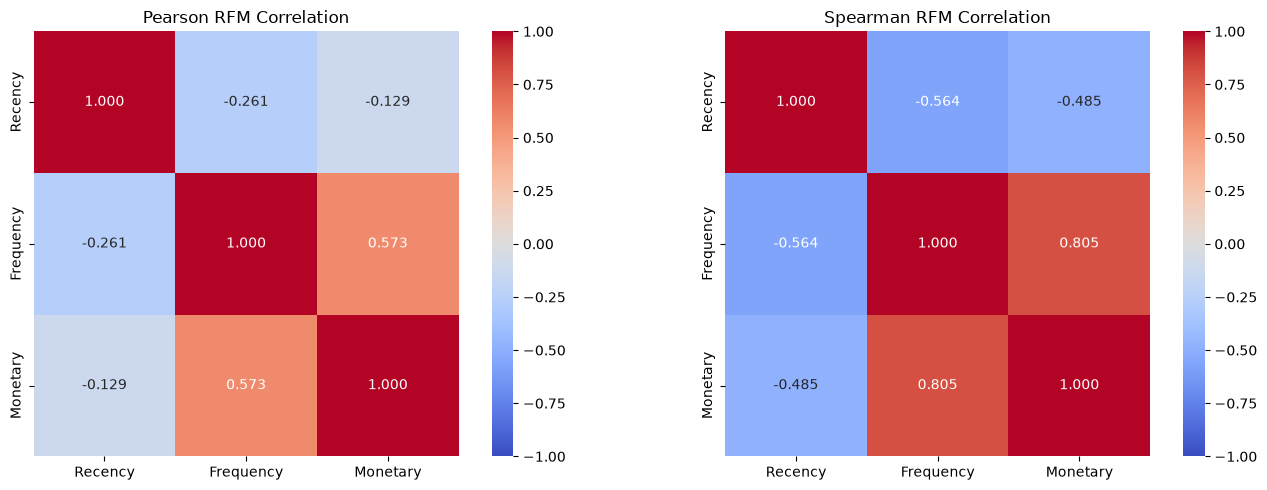

RFM Correlation Comparison:


,Variable Pair,Pearson,Spearman
0,Recency vs Frequency,-0.2614,-0.5636
1,Recency vs Monetary,-0.1290,-0.4854
2,Frequency vs Monetary,0.5730,0.8055


In [42]:

# Use Commission-Adjusted RFM Data
rfm_corr = rfm_test[
    ["Recency", "Frequency", "Monetary"]
].copy()

# Calculate Correlations
pearson_corr = rfm_corr.corr(method="pearson")
spearman_corr = rfm_corr.corr(method="spearman")

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, corr, method in zip(
    axes,
    [pearson_corr, spearman_corr],
    ["Pearson", "Spearman"]
):
    sns.heatmap(
        corr,
        annot=True,
        fmt=".3f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        ax=ax
    )

    ax.set_title(f"{method} RFM Correlation")

plt.tight_layout()
plt.show()

# Correlation Comparison
pairs = [
    ("Recency", "Frequency"),
    ("Recency", "Monetary"),
    ("Frequency", "Monetary")
]

results = pd.DataFrame([
    {
        "Variable Pair": f"{a} vs {b}",
        "Pearson": pearson_corr.loc[a, b],
        "Spearman": spearman_corr.loc[a, b]
    }
    for a, b in pairs
])

print("RFM Correlation Comparison:")
display(results.round(4))



### Key Insights & Recommendations

RFM Correlation Analysis menunjukkan hubungan positif kuat antara Frequency dan Monetary (Spearman 0.805), sedangkan Recency berkorelasi negatif dengan Frequency (-0.564) dan Monetary (-0.485). Hal ini menunjukkan pelanggan yang lebih sering berbelanja cenderung memiliki nilai pembelian lebih tinggi dan waktu sejak pembelian terakhir yang lebih singkat. Perusahaan disarankan meningkatkan repeat purchase melalui loyalty program serta memprioritaskan reaktivasi pelanggan bernilai tinggi yang sudah lama tidak bertransaksi.



## 29. Final RFM Dataset Synchronization


In [43]:

# Create Final RFM Dataset
rfm_final = rfm_test[rfm.columns].copy()

# Recalculate Final Segment Summary
segment_summary_final = (
    rfm_final.groupby("Segment")
    .agg(
        Customers=("CustomerID", "nunique"),
        NetMonetary=("Monetary", "sum"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median")
    )
    .reset_index()
)

# Calculate Segment Contribution
segment_summary_final["Customer (%)"] = (
    segment_summary_final["Customers"] /
    len(rfm_final) * 100
).round(2)

segment_summary_final["Monetary (%)"] = (
    segment_summary_final["NetMonetary"] /
    rfm_final["Monetary"].sum() * 100
).round(2)

# Final Summary
print("Final RFM Segment Summary:")
display(
    segment_summary_final.sort_values(
        "NetMonetary", ascending=False
    ).round(2)
)

# Final Validation
print("\nTotal Customers:", len(rfm_final))
print("Total Segments:", rfm_final["Segment"].nunique())
print("Total Net Monetary: £",
      round(rfm_final["Monetary"].sum(), 2))
print("Missing Values:", rfm_final.isna().sum().sum())
print("Final Dataset Shape:", rfm_final.shape)

# Compare Original and Final Segmentation
print("\nChanged Segments:",
      (rfm_final["Segment"] != rfm["Segment"]).sum())


Final RFM Segment Summary:


,Segment,Customers,NetMonetary,MedianRecency,MedianFrequency,MedianMonetary,Customer (%),Monetary (%)
1,Champions,910,5468558.61,11.0,8.0,2634.25,21.00,66.01
4,Loyal Customers,379,769378.76,41.0,5.0,1227.43,8.74,9.29
0,At Risk,614,515189.84,152.0,2.0,596.97,14.17,6.22
6,Potential Loyalists,484,407673.42,18.0,2.0,630.66,11.17,4.92
5,Needs Attention,599,370640.44,53.0,2.0,424.40,13.82,4.47
2,Hibernating,968,346536.32,233.0,1.0,248.26,22.34,4.18
3,High-Value At Risk,142,331347.73,104.0,5.0,1833.16,3.28,4.00
7,Recent Low-Frequency,238,75564.96,20.0,1.0,226.23,5.49,0.91



Total Customers: 4334
Total Segments: 8
Total Net Monetary: £ 8284890.08
Missing Values: 0
Final Dataset Shape: (4334, 12)

Changed Segments: 0



### Key Insights & Recommendations

Final RFM Validation menghasilkan 4,334 pelanggan dalam 8 segmen dengan total Net Monetary sebesar £8,284,890.08 tanpa missing values. Champions menyumbang 66.01% Net Monetary, sementara koreksi Commission tidak mengubah segmentasi pelanggan. Perusahaan disarankan menggunakan dataset RFM yang telah tervalidasi untuk memprioritaskan pelanggan bernilai tinggi dan menyusun strategi customer retention.



## 30. Final Retention Action Plan Synchronization


In [44]:

# Recalculate Final Retention Action Plan
action_plan_final = (
    rfm_final.groupby(
        ["Segment", "RetentionPriority", "RecommendedAction"]
    )
    .agg(
        Customers=("CustomerID", "nunique"),
        TotalMonetary=("Monetary", "sum"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median")
    )
    .reset_index()
)

# Calculate Contribution
action_plan_final["Customer (%)"] = (
    action_plan_final["Customers"] /
    len(rfm_final) * 100
).round(2)

action_plan_final["Monetary (%)"] = (
    action_plan_final["TotalMonetary"] /
    rfm_final["Monetary"].sum() * 100
).round(2)

# Define Priority Order
priority_order = {
    "Critical": 1,
    "High": 2,
    "Medium": 3,
    "Low": 4
}

action_plan_final["PriorityOrder"] = (
    action_plan_final["RetentionPriority"]
    .map(priority_order)
)

action_plan_final = (
    action_plan_final
    .sort_values(
        ["PriorityOrder", "TotalMonetary"],
        ascending=[True, False]
    )
    .drop(columns="PriorityOrder")
)

# Display Final Action Plan
print("Final Customer Retention Action Plan:")
display(action_plan_final.round(2))

# Validation
print("\nTotal Customers:",
      action_plan_final["Customers"].sum())

print("Total Net Monetary:",
      round(action_plan_final["TotalMonetary"].sum(), 2))

print("Missing Priorities:",
      rfm_final["RetentionPriority"].isna().sum())

print("Missing Actions:",
      rfm_final["RecommendedAction"].isna().sum())


Final Customer Retention Action Plan:


,Segment,RetentionPriority,RecommendedAction,Customers,TotalMonetary,MedianRecency,MedianFrequency,MedianMonetary,Customer (%),Monetary (%)
3,High-Value At Risk,Critical,Personalized Win-Back Campaign,142,331347.73,104.0,5.0,1833.16,3.28,4.00
1,Champions,High,VIP Rewards & Exclusive Benefits,910,5468558.61,11.0,8.0,2634.25,21.00,66.01
4,Loyal Customers,High,Loyalty & Referral Program,379,769378.76,41.0,5.0,1227.43,8.74,9.29
6,Potential Loyalists,High,Second Purchase Incentives,484,407673.42,18.0,2.0,630.66,11.17,4.92
0,At Risk,Medium,Targeted Reactivation Campaign,614,515189.84,152.0,2.0,596.97,14.17,6.22
5,Needs Attention,Medium,Personalized Product Recommendations,599,370640.44,53.0,2.0,424.40,13.82,4.47
7,Recent Low-Frequency,Medium,Welcome & Repeat Purchase Offers,238,75564.96,20.0,1.0,226.23,5.49,0.91
2,Hibernating,Low,Low-Cost Re-engagement Campaign,968,346536.32,233.0,1.0,248.26,22.34,4.18



Total Customers: 4334
Total Net Monetary: 8284890.08
Missing Priorities: 0
Missing Actions: 0



### Key Insights & Recommendations

Final Retention Action Plan mengelompokkan 4,334 pelanggan ke dalam 8 segmen dengan total Net Monetary £8,284,890.08. Champions menyumbang 66.01% dari total Monetary, sedangkan 142 High-Value At Risk Customers menjadi prioritas reaktivasi. Perusahaan disarankan menjalankan VIP loyalty program, personalized win-back campaign, dan insentif repeat purchase berdasarkan prioritas setiap segmen untuk meningkatkan customer retention.



## 31. Export Final Analytical Datasets


In [45]:

from pathlib import Path

# Create Export Folder
output_dir = Path("powerbi_exports")
output_dir.mkdir(exist_ok=True)

# 1. Final Customer-Level RFM Dataset
customers_export = rfm_final.copy()

# 2. Final Net Transaction Dataset
transactions_export = df_net_refined[
    df_net_refined["CustomerID"].isin(
        rfm_final["CustomerID"]
    )
].copy()

transactions_export["YearMonth"] = (
    transactions_export["InvoiceDate"]
    .dt.to_period("M").astype(str)
)

# 3. Final Segment Summary
segments_export = segment_summary_final.copy()

# 4. Final Retention Action Plan
actions_export = action_plan_final.copy()

# Standardize CustomerID for Power BI
for data in [customers_export, transactions_export]:
    data["CustomerID"] = data["CustomerID"].astype("int64")

# Export CSV Files
exports = {
    "rfm_customers_final.csv": customers_export,
    "rfm_transactions_final.csv": transactions_export,
    "rfm_segments_final.csv": segments_export,
    "rfm_action_plan_final.csv": actions_export
}

for filename, data in exports.items():
    data.to_csv(output_dir / filename, index=False)

# Export Validation
print("Export Summary:")

for filename, data in exports.items():
    print(f"{filename}: {data.shape}")

# Monetary Reconciliation
customer_total = customers_export["Monetary"].sum()
transaction_total = transactions_export["NetRevenue"].sum()

print("\nCustomer Monetary:",
      round(customer_total, 2))

print("Transaction Monetary:",
      round(transaction_total, 2))

print("Reconciliation Difference:",
      round(customer_total - transaction_total, 2))

print("\nExport Folder:", output_dir.resolve())


Export Summary:
rfm_customers_final.csv: (4334, 12)
rfm_transactions_final.csv: (404857, 10)
rfm_segments_final.csv: (8, 8)
rfm_action_plan_final.csv: (8, 10)

Customer Monetary: 8284890.08
Transaction Monetary: 8284890.08
Reconciliation Difference: -0.0

Export Folder: C:\Users\rabat\powerbi_exports



### Key Insights & Recommendations

Final Data Export menghasilkan 4 dataset analitis yang mencakup 4,334 pelanggan, 404,857 baris transaksi, dan 8 segmen RFM dengan total Net Monetary £8,284,890.08. Hasil rekonsiliasi sebesar £0 menunjukkan konsistensi nilai Monetary antara data pelanggan dan transaksi. Perusahaan disarankan memanfaatkan dashboard interaktif untuk memantau customer value, kontribusi segmen, serta prioritas strategi customer retention.
